# 三条技术路线的严格对比：TF-IDF + 经典 ML / 字符级深度网络 / 大语言模型

## 研究问题

在同一批人工标注的中文餐饮评论文本上，三条技术路线对**负面性**与**侮辱性**两个二分类任务
的判别能力是否存在统计学上可辨识的差异？差异体现在哪些维度与样本亚组上？

比较对象：

| 路线 | 具体模型 | 提示模式 |
|---|---|---|
| **ML** | 逻辑回归 / 朴素贝叶斯 / 线性 SVM / 随机森林（TF-IDF 特征） | — |
| **DL** | 字符级 BiGRU + 注意力池化（双任务头） | — |
| **LLM** | MiMo / DeepSeek / Qwen | 零样本、提示词工程 |

---

## 分析计划（在查看任何结果之前声明）

> 这一节的目的，是把"看到数字之后再挑对自己有利的检验"这条路堵死。
> 以下终点、检验方法与校正方式均为**先验指定**，后文不得替换。

### 主要终点（primary endpoint）

**侮辱性任务的 F1（正类）**。理由：侮辱性正类仅占 10.6%，是二者中更难、区分度更高的任务；
负面性上所有方法都已接近天花板，难以体现路线差异。

### 次要终点（secondary endpoints）

- 负面性 F1
- 两个维度的召回率、精确率、MCC、Balanced Accuracy
- AUPRC（仅对可输出连续分数的方法计算）

### 统计推断方案

| 目的 | 方法 | 说明 |
|---|---|---|
| 区间估计 | **按标签分层的 Bootstrap 95% CI**（B=2000） | 保持正类数量，避免重采样后正类塌缩 |
| 全局差异 | **Cochran's Q 检验** | 检验 k 个方法在同一样本上的正确/错误是否整体同质 |
| 两两比较 | **McNemar 精确检验**（配对） | 只比较同一批样本上的配对判别结果 |
| 多重比较 | **Holm–Bonferroni step-down** | 控制 family-wise error rate，α=0.05 |
| 效应量 | 配对 **ΔF1 的 Bootstrap 95% CI** + McNemar **优势比 OR** | 报告"差多少"，而不只是"是否显著" |

### 显著性水平

α = 0.05（双侧）。所有 p 值在**每个维度内部**构成一个 family 进行校正。

### 预先声明的分析约束

1. **可比性优先于分数**：任何方法若存在信息泄漏（见过测试样本），其结果不进入主表。
2. **单次运行的数字不作为结论**：凡带随机性的方法，必须报告随机性来源下的波动范围。
3. **不平衡任务不以便用 Accuracy 作主判据**：Accuracy 会同时报告，但明确标注其在该任务上不可单独解释。


---

## 目录

1. 可复现性基础
2. 评估基座：金标准数据与标注者信度
3. 评估协议：可比性条件与泄漏控制
4. 方法 A —— TF-IDF + 经典机器学习
5. 方法 B —— 字符级深度网络（多种子嵌套交叉验证）
6. 方法 C —— 大语言模型（3 模型 × 2 提示模式）
7. 主评估表
8. 统计推断
9. 分层分析
10. 错误结构分析
11. 敏感性分析
12. 结论与局限
13. 结果导出


---

## 1. 可复现性基础

记录运行环境的全部关键版本、随机种子策略与数据指纹。种子策略预先固定，
不使用"换种子换到好看为止"的做法。

In [1]:
# ===== 1. 环境与全局配置 / Environment & global configuration =====
import hashlib
import json
import platform
import random
import re
import sys
import time
import unicodedata
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

from scipy import stats
from scipy.stats import chi2, binomtest

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# ---- 路径：兼容「在 scripts/ 下运行」与「在仓库根运行」两种情形 ----
_CWD = Path.cwd()
PROJ = _CWD if (_CWD / "Data").exists() else _CWD.parent
if not (PROJ / "Data").exists():
    raise SystemExit(f"未找到 Data 目录，请在仓库内运行。cwd={_CWD}")

OUT_DIR = PROJ / "Data" / "Comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DL_CACHE = OUT_DIR / "dl_oof"

# ---- 中文字体 / CJK font ----
_have = {f.name for f in font_manager.fontManager.ttflist}
for _n in ["PingFang SC", "Hiragino Sans GB", "Heiti SC", "Arial Unicode MS",
           "Songti SC", "STHeiti", "Noto Sans CJK SC", "SimHei"]:
    if _n in _have:
        plt.rcParams["font.sans-serif"] = [_n]
        print(f"中文字体 / CJK font: {_n}")
        break
else:
    print("⚠️ 未找到中文字体，图中中文可能显示为方框")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

# ---- 全局常量：一旦设定，全程不再改动 ----
SEED = 42                      # 主种子（切分、bootstrap）
N_FOLDS = 5                    # 交叉验证折数
N_BOOT = 2000                  # Bootstrap 重采样次数
ALPHA = 0.05                   # 显著性水平
DIMS = ["负面性", "侮辱性"]
TYPE_ORDER = ["好评", "正常差评", "声音型差评", "语气型差评", "视觉型差评"]

print(f"\nPython      {sys.version.split()[0]}")
print(f"numpy       {np.__version__}")
print(f"pandas      {pd.__version__}")
print(f"scipy       {stats.__version__ if hasattr(stats,'__version__') else 'n/a'}")
try:
    import sklearn; print(f"scikit-learn{sklearn.__version__:>6}")
except Exception as e:
    print("scikit-learn 缺失:", e)
try:
    import torch; print(f"torch       {torch.__version__}  (MPS={torch.backends.mps.is_available()})")
except Exception as e:
    print("torch 缺失:", e)
print(f"platform    {platform.platform()}")
print(f"项目根目录   {PROJ}")


中文字体 / CJK font: Hiragino Sans GB

Python      3.9.6
numpy       2.0.2
pandas      2.3.3
scipy       n/a
scikit-learn 1.6.1
torch       2.8.0  (MPS=True)
platform    macOS-27.0.1-arm64-arm-64bit
项目根目录   /Users/Edward/Github/LLM-Sentiment-Analysis


---

## 2. 评估基座：金标准数据与标注者信度

### 2.1 为什么必须先看信度

所有方法都是相对**同一份人工标注**打分的。如果标注本身噪声很大，
那么方法之间的差异有一部分是"标注噪声"而非"能力差异"。
因此先计算标注者间一致性（inter-annotator agreement），
它给出这份数据的**性能上限（ceiling）**：任何模型的 F1 都不应显著超过
"用一位标注员去预测另一位标注员"所能达到的水平。

报告三项：

- **Krippendorff's α**（名义尺度）：容许多位标注者、容许缺失值，是内容分析领域的标准指标
- **Fleiss' κ**：固定标注者数量的多评分者一致性
- **逐样本分歧分布**：多少条是 4:0 一致、3:1 分裂、2:2 平票

In [2]:
# ===== 2.1 数据加载与对齐校验 / load & alignment checks =====
P_HUMAN = PROJ / "Data" / "Human" / "Human_Result.csv"
P_VOTES = PROJ / "Data" / "Human" / "Human.csv"
P_ML    = PROJ / "Data" / "ML"    / "ML_predictions.csv"
P_LLM0  = PROJ / "Data" / "LLM"   / "LLM_predictions.csv"
P_LLM1  = PROJ / "Data" / "LLM"   / "LLM_prompt_predictions.csv"

human = pd.read_csv(P_HUMAN)
votes = pd.read_csv(P_VOTES)

assert len(human) == len(votes), "两表行数不一致"
assert (human["评论"].astype(str).str.strip() == votes["评论"].astype(str).str.strip()).all(), \
    "金标准表与投票表未逐行对齐"

TEXT = human["评论"].astype(str).str.strip()
Y = human[[f"{d}标签" for d in DIMS]].to_numpy(dtype=int)
N = len(human)

# ---- 归一化文本（仅用于分组切分，绝不作为模型输入）----
# Normalized text — used ONLY for group-aware splitting, never as a model feature.
def norm_key(t: str) -> str:
    s = unicodedata.normalize("NFKC", str(t))
    return re.sub(r"[^\w\u4e00-\u9fff]+", "", s.lower())

GROUPS = np.array([norm_key(t) for t in TEXT], dtype=object)
N_UNIQUE = len(pd.unique(pd.Series(GROUPS)))

# ---- 分层键：两标签的联合类别，保证每折都含侮辱性正例 ----
STRAT = Y[:, 0] * 2 + Y[:, 1]

def md5_of(p: Path) -> str:
    return hashlib.md5(p.read_bytes()).hexdigest()

FINGERPRINT = {p.name: md5_of(p) for p in [P_HUMAN, P_VOTES, P_ML, P_LLM0, P_LLM1]}

print(f"样本数 N = {N}（唯一归一化文本 {N_UNIQUE} 条）")
for k, d in enumerate(DIMS):
    print(f"  {d} 正类 = {int(Y[:, k].sum())} ({Y[:, k].mean():.1%})")
print("\n数据指纹 / fingerprints:")
for k, v in FINGERPRINT.items():
    print(f"  {k:<28s} {v[:16]}…")


样本数 N = 420（唯一归一化文本 406 条）
  负面性 正类 = 236 (56.2%)
  侮辱性 正类 = 45 (10.7%)

数据指纹 / fingerprints:
  Human_Result.csv             dbb563ba66a9de99…
  Human.csv                    74a7ac2cc678ef08…
  ML_predictions.csv           a276d2f9879a63a1…
  LLM_predictions.csv          cdcbc6c00f916fad…
  LLM_prompt_predictions.csv   ce6cc893e3be9dee…


In [3]:
# ===== 2.1b 标注者间信度 / inter-annotator agreement =====
def fleiss_kappa(M: np.ndarray) -> float:
    """Fleiss' kappa。M: (n_items, n_categories) 每类被投的票数。"""
    n_items, n_cat = M.shape
    n_raters = M.sum(axis=1)
    assert np.all(n_raters == n_raters[0]), "各样本的标注者数量必须一致"
    m = n_raters[0]
    if m < 2:
        return np.nan
    p_j = M.sum(axis=0) / (n_items * m)
    P_bar = (np.sum(M * (M - 1), axis=1) / (m * (m - 1))).mean()
    P_e = (p_j ** 2).sum()
    return float((P_bar - P_e) / (1 - P_e)) if P_e < 1 else np.nan


def krippendorff_alpha_nominal(data: np.ndarray) -> float:
    """
    Krippendorff's alpha（名义尺度，容许缺失）。
    data: (n_raters, n_items)，np.nan 表示缺失。
    """
    n_raters, n_items = data.shape
    # 一致性观测对 / observed disagreement
    total_pairs = 0
    agree_pairs = 0
    for j in range(n_items):
        col = data[:, j]
        col = col[~pd.isna(col)]
        m = len(col)
        if m < 2:
            continue
        vals, cnts = np.unique(col, return_counts=True)
        agree_pairs += sum(c * (c - 1) for c in cnts)
        total_pairs += m * (m - 1)
    if total_pairs == 0:
        return np.nan
    Do = 1.0 - agree_pairs / total_pairs
    # 期望不一致 / expected disagreement
    all_vals = data[~pd.isna(data)]
    vals, cnts = np.unique(all_vals, return_counts=True)
    nn = len(all_vals)
    De = 1.0 - sum(c * (c - 1) for c in cnts) / (nn * (nn - 1))
    return float(1.0 - Do / De) if De > 0 else np.nan


agree_rows = []
for d in DIMS:
    cols = [f"{d}{i}" for i in range(1, 5)]
    V = votes[cols].to_numpy(dtype=float)                    # (n_items, 4)
    M = np.stack([(V == 0).sum(axis=1), (V == 1).sum(axis=1)], axis=1)   # (n_items, 2)

    alpha = krippendorff_alpha_nominal(V.T)
    kappa = fleiss_kappa(M.astype(int))
    # 逐样本一致度：4:0 一致 / 3:1 分裂 / 2:2 平票
    n_pos = V.sum(axis=1)
    unanimous = int(((n_pos == 0) | (n_pos == 4)).sum())
    split31 = int(((n_pos == 1) | (n_pos == 3)).sum())
    tie22 = int((n_pos == 2).sum())
    # 与多数票的一致率（>=0.5 判定；平票时按多数票文件为准）
    maj = (V.mean(axis=1) >= 0.5).astype(int)
    repro = int((maj == Y[:, DIMS.index(d)]).sum())
    agree_rows.append({"维度": d, "Krippendorff_α": round(alpha, 4), "Fleiss_κ": round(kappa, 4),
                       "4比0一致": unanimous, "3比1分裂": split31, "2比2平票": tie22,
                       "多数票复现率": f"{repro}/{N}"})

agree_df = pd.DataFrame(agree_rows)
print("【标注者间信度 / inter-annotator agreement】")
print(agree_df.to_string(index=False))
print("""
解读：
- Krippendorff α 的常用门槛：α ≥ 0.80 视为可靠，0.667 ≤ α < 0.80 仅可作探索性结论。
- 「多数票复现率」= 用 4 位标注员的多数票能否重建金标准标签，衡量金标准的内部一致性。
- 2:2 平票的样本，其真值本质上是不确定的，这对所有方法一视同仁地构成噪声。
""")


【标注者间信度 / inter-annotator agreement】
 维度  Krippendorff_α  Fleiss_κ  4比0一致  3比1分裂  2比2平票  多数票复现率
负面性          0.9591    0.9591    405      9      6 420/420
侮辱性          0.8589    0.8589    401     13      6 417/420

解读：
- Krippendorff α 的常用门槛：α ≥ 0.80 视为可靠，0.667 ≤ α < 0.80 仅可作探索性结论。
- 「多数票复现率」= 用 4 位标注员的多数票能否重建金标准标签，衡量金标准的内部一致性。
- 2:2 平票的样本，其真值本质上是不确定的，这对所有方法一视同仁地构成噪声。



In [4]:
# ===== 2.2 数据结构：标签与类型的嵌套关系 / label × type nesting =====
nest = (human.groupby("类型")
        .agg(n=("评论", "size"),
             负面性正类=("负面性标签", "sum"),
             侮辱性正类=("侮辱性标签", "sum"))
        .reindex(TYPE_ORDER))
nest["负面性正类占比"] = (nest["负面性正类"] / nest["n"]).round(3)
nest["侮辱性正类占比"] = (nest["侮辱性正类"] / nest["n"]).round(3)
print("【类型 × 标签 分布】")
print(nest.to_string())
print(f"""
合计 {N} 条 | 负面性正类 {int(Y[:,0].sum())} | 侮辱性正类 {int(Y[:,1].sum())}

注意两点，它们会影响后续的分层分析如何解读：
1. 「类型」是**预先指定**的分组（原始投票表中没有类型投票列），不是标注结果。
   好评组负面性正类为 0、四个差评组接近 100%，因此组内 Accuracy 在不同组之间
   含义不同（好评组 = 特异度，差评组 = 灵敏度），不能横向直接比较。
2. 侮辱性正类只出现在三个对抗类型中，正常差评组为 0。
   因此侮辱性的分类型分析只能在这三组上进行，且语气型正类仅 {int(nest.loc['语气型差评','侮辱性正类'])} 条。
""")

# 重复文本：仅用于 group-aware 切分与敏感性分析，不做删除
dup_rows = int(pd.Series(GROUPS).duplicated(keep=False).sum())
print(f"重复文本涉及 {dup_rows} 行（{N} - {N_UNIQUE} = {N - N_UNIQUE} 行为冗余出现）。")
print("→ 这些行是不同用户写出的相同评论，属于合法独立样本，**不删除**；")
print("  但交叉验证时必须按文本分组，防止同一文本同时落入训练折与验证折。")


【类型 × 标签 分布】
         n  负面性正类  侮辱性正类  负面性正类占比  侮辱性正类占比
类型                                        
好评     182      0      0    0.000    0.000
正常差评   114    112      0    0.982    0.000
声音型差评   30     30     22    1.000    0.733
语气型差评   73     73      6    1.000    0.082
视觉型差评   21     21     17    1.000    0.810

合计 420 条 | 负面性正类 236 | 侮辱性正类 45

注意两点，它们会影响后续的分层分析如何解读：
1. 「类型」是**预先指定**的分组（原始投票表中没有类型投票列），不是标注结果。
   好评组负面性正类为 0、四个差评组接近 100%，因此组内 Accuracy 在不同组之间
   含义不同（好评组 = 特异度，差评组 = 灵敏度），不能横向直接比较。
2. 侮辱性正类只出现在三个对抗类型中，正常差评组为 0。
   因此侮辱性的分类型分析只能在这三组上进行，且语气型正类仅 6 条。

重复文本涉及 21 行（420 - 406 = 14 行为冗余出现）。
→ 这些行是不同用户写出的相同评论，属于合法独立样本，**不删除**；
  但交叉验证时必须按文本分组，防止同一文本同时落入训练折与验证折。


---

## 3. 评估协议：可比性条件与泄漏控制

### 3.1 可比性四条件

三条路线要能放在同一张表里比较，必须同时满足：

| 条件 | 含义 | 本 notebook 的处理 |
|---|---|---|
| **C1 同一评估集** | 所有方法在完全相同的 N 条样本上评估，且顺序一致 | 统一以 `Human_Result.csv` 的行序为基准，逐行断言 |
| **C2 同一金标准** | 使用同一份标签，不因方法而异 | 统一使用 4 人多数票结果 |
| **C3 无信息泄漏** | 任何测试样本都不得进入其自身预测所依赖的训练过程 | ML/DL 使用 **out-of-fold (OOF)** 预测；LLM 为零样本，天然无监督接触 |
| **C4 无调参泄漏** | 超参数与阈值的选择不得使用测试折信息 | ML 超参数先验固定；DL 早停使用**训练折内部再切出的验证子集**，测试折不参与模型选择 |

C3 与 C4 是最容易被忽视、也最影响结论的两条。本 notebook 对旧流程做了两处修正：

- **修正一**：ML 原先使用 `StratifiedKFold`，同一条文本的多次出现可能跨越训练折与验证折。
  本 notebook 统一改用 `StratifiedGroupKFold`，以**归一化文本**为分组单位。
- **修正二**：DL 原先只运行单一随机种子。本 notebook 采用**多种子嵌套交叉验证**，
  报告种子间波动，而不是把一次运行的结果当作方法的能力。

### 3.2 评价指标

| 指标 | 角色 | 说明 |
|---|---|---|
| **F1（正类）** | 主要 | 不平衡任务下比 Accuracy 可靠 |
| Precision / Recall | 主要 | 揭示"保守"还是"激进"的判别倾向 |
| **MCC** | 主要 | 二分类中公认稳健的单一指标，对类别不平衡不敏感 |
| **Balanced Accuracy** | 主要 | (灵敏度 + 特异度) / 2 |
| Cohen's κ | 主要 | 相对随机基线的校正一致度 |
| AUPRC / AUROC | 仅限可输出连续分数的方法 | LLM 只输出二值标签，此项为 N/A |
| Accuracy | 参考 | **不作为主判据**：全部预测为 0 即可得 89.4% |

In [5]:
# ===== 3. 评估工具函数 / evaluation utilities =====
def conf_counts(y_true, y_pred):
    """返回 (TP, FP, FN, TN)。 Returns the four confusion counts."""
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    return tp, fp, fn, tn


def metrics_point(y_true, y_pred):
    """点估计：完整指标集。Point estimates of the full metric set."""
    tp, fp, fn, tn = conf_counts(y_true, y_pred)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / (tp + fn) if (tp + fn) else 0.0
    f1   = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    acc  = (tp + tn) / max(tp + fp + fn + tn, 1)
    bacc = (rec + spec) / 2
    # MCC
    den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    mcc = ((tp * tn - fp * fn) / den) if den > 0 else 0.0
    # Cohen's kappa vs 真值
    pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / max((tp + fp + fn + tn) ** 2, 1)
    kap = (acc - pe) / (1 - pe) if pe < 1 else 0.0
    # Macro-F1
    f1_neg = 2 * tn / (2 * tn + fn + fp) if (2 * tn + fn + fp) else 0.0
    return {"Precision": prec, "Recall": rec, "F1": f1, "MacroF1": (f1 + f1_neg) / 2,
            "Accuracy": acc, "BalancedAcc": bacc, "MCC": mcc, "Kappa": kap,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


def auroc_auprc(y_true, score):
    """AUROC 与 AUPRC（基于排序，不需要概率校准）。"""
    try:
        from sklearn.metrics import average_precision_score, roc_auc_score
        if len(np.unique(y_true)) < 2:
            return np.nan, np.nan
        return float(roc_auc_score(y_true, score)), float(average_precision_score(y_true, score))
    except Exception:
        return np.nan, np.nan


def stratified_boot_index(y_true, n_boot=N_BOOT, seed=SEED):
    """
    分层 Bootstrap 索引：(n_boot, n) 的整数矩阵，每行是一次完整的样本索引。
    正类与负类分别有放回抽取同样多的样本，保持正类比例不变。
    """
    rng = np.random.default_rng(seed)
    pos = np.where(np.asarray(y_true) == 1)[0]
    neg = np.where(np.asarray(y_true) == 0)[0]
    idx = np.empty((n_boot, len(y_true)), dtype=np.int32)
    for b in range(n_boot):
        idx[b] = np.concatenate([rng.choice(pos, len(pos), True),
                                 rng.choice(neg, len(neg), True)])
    return idx


def boot_metrics_from_index(y_true, y_pred, idx_mat):
    """
    用同一套索引快速计算 B 次重采样的核心指标（向量化）。
    返回 dict: 指标名 -> (B,) 数组。
    """
    yt = np.asarray(y_true)[idx_mat]        # (B, n)
    yp = np.asarray(y_pred)[idx_mat]
    tp = ((yt == 1) & (yp == 1)).sum(1).astype(float)
    fp = ((yt == 0) & (yp == 1)).sum(1).astype(float)
    fn = ((yt == 1) & (yp == 0)).sum(1).astype(float)
    tn = ((yt == 0) & (yp == 0)).sum(1).astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.where(tp + fp > 0, tp / (tp + fp), 0.0)
        rec  = np.where(tp + fn > 0, tp / (tp + fn), 0.0)
        f1   = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), 0.0)
        spec = np.where(tn + fp > 0, tn / (tn + fp), 0.0)
        acc  = (tp + tn) / np.maximum(tp + fp + fn + tn, 1)
        bacc = (rec + spec) / 2
        mcc_den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
        mcc = np.where(mcc_den > 0, (tp * tn - fp * fn) / mcc_den, 0.0)
        pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / np.maximum((tp + fp + fn + tn) ** 2, 1)
        kap = np.where(pe < 1, (acc - pe) / (1 - pe), 0.0)
        f1_neg = np.where(2 * tn + fn + fp > 0, 2 * tn / (2 * tn + fn + fp), 0.0)
        macf1 = (f1 + f1_neg) / 2
    return {"Precision": prec, "Recall": rec, "F1": f1, "MacroF1": macf1, "Accuracy": acc,
            "BalancedAcc": bacc, "MCC": mcc, "Kappa": kap}


def holm_bonferroni(pvals):
    """Holm–Bonferroni step-down 校正。返回校正后的 p 值数组（保持原顺序）。"""
    p = np.asarray(pvals, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m, dtype=float)
    running = 0.0
    for rank, i in enumerate(order):
        val = (m - rank) * p[i]
        running = max(running, val)          # 保证单调不降
        adj[i] = min(running, 1.0)
    return adj


def cochran_q(pred_matrix, y_true):
    """
    Cochran's Q：k 个方法在同一样本集上的判别结果是否整体同质。
    pred_matrix: (k, n) 二值预测；返回 (Q, df, p)。
    """
    P = np.asarray(pred_matrix, dtype=int)
    y = np.asarray(y_true, dtype=int)
    correct = (P == y).astype(float)          # (k, n)
    k, n = correct.shape
    C = correct.sum(axis=1)                   # 每个方法的正确数
    R = correct.sum(axis=0)                   # 每个样本被多少个方法判对
    T = C.sum()
    denom = k * T - (R ** 2).sum()
    if denom <= 0:
        return 0.0, k - 1, 1.0
    Q = (k - 1) * (k * (C ** 2).sum() - T ** 2) / denom
    return float(Q), k - 1, float(chi2.sf(Q, k - 1))


def mcnemar_exact(y_true, pred_a, pred_b):
    """
    配对 McNemar 精确检验（二项式版本）。返回 (b01, b10, OR, p)。
    b01 = A 错 B 对；b10 = A 对 B 错。
    """
    yt = np.asarray(y_true); a = np.asarray(pred_a); b = np.asarray(pred_b)
    ca, cb = (a == yt), (b == yt)
    b01 = int((~ca & cb).sum())
    b10 = int((ca & ~cb).sum())
    n_disc = b01 + b10
    p = float(binomtest(b01, n_disc, 0.5).pvalue) if n_disc > 0 else 1.0
    or_ = (b01 / b10) if b10 > 0 else (np.inf if b01 > 0 else np.nan)
    return b01, b10, or_, p


print("评估工具函数已就绪：点估计 / 分层 Bootstrap / Holm 校正 / Cochran Q / McNemar")


评估工具函数已就绪：点估计 / 分层 Bootstrap / Holm 校正 / Cochran Q / McNemar


---

## 4. 方法 A —— TF-IDF + 经典机器学习

### 4.1 流程

1. jieba 分词（保留否定词与 emoji，不做停用词以外的清洗）
2. TF-IDF 向量化（1–2 gram，sublinear TF，min_df=2）
3. 四个分类器：逻辑回归 / 多项式朴素贝叶斯 / 线性 SVM / 随机森林
4. **TF-IDF 与分类器整体放入 Pipeline，随每一折重新拟合**
5. 切分：`StratifiedGroupKFold(5)`，分组键 = 归一化文本，分层键 = 两个标签的联合类别

第 4 点是泄漏控制的关键：若先用全部数据拟合 TF-IDF 词表再交叉验证，
验证折的词汇已经影响了向量空间，属于典型的预处理泄漏。

### 4.2 与旧流程的差异

| 项 | 旧流程 | 本流程 |
|---|---|---|
| 切分器 | `StratifiedKFold`（按标签分层，**未分组**） | `StratifiedGroupKFold`（按文本分组 + 按联合标签分层） |
| 负面影响 | 重复文本可能跨折，指标偏乐观 | 同一文本强制落入同一折 |

In [6]:
# ===== 4.1 分词 / tokenization =====
import jieba

NEGATION_WORDS = {"不", "没", "没有", "别", "莫", "勿", "未", "无"}
STOPWORDS = {
    "的", "了", "是", "我", "你", "他", "她", "它", "我们", "你们", "这", "那",
    "也", "都", "就", "在", "有", "人", "啊", "吗", "呢", "吧", "呀", "哦",
    "和", "跟", "与", "或", "而且", "但是", "所以", "因为", "如果", "虽然",
    "一个", "一下", "还是", "这个", "那个", "什么", "怎么", "这么", "那么",
    "【", "】", "#", "＋", "+", "?", "？", "又",
} - NEGATION_WORDS          # 否定词绝不停用，它们承载极性

EMOJI_RE = re.compile(
    "[\U0001F300-\U0001FAFF\U00002700-\U000027BF\U0001F000-\U0001F02F"
    "\U00002600-\U000026FF\U0001F900-\U0001F9FF\U00002764\U0001F525]"
)

def tokenize(text: str):
    """中文分词；emoji 独立成 token；过滤停用词、纯标点与纯数字。"""
    toks = EMOJI_RE.findall(text)
    body = EMOJI_RE.sub(" ", str(text))
    for tok in jieba.lcut(body):
        tok = tok.strip()
        if not tok or tok in STOPWORDS or tok.isdigit():
            continue
        if re.fullmatch(r"[\W_]+", tok, re.UNICODE):
            continue
        toks.append(tok)
    return toks

t0 = time.time()
TOKENS = [tokenize(t) for t in TEXT]
TOK_TEXT = [" ".join(tk) for tk in TOKENS]
print(f"分词完成，用时 {time.time()-t0:.1f}s | 平均 token 数 {np.mean([len(x) for x in TOKENS]):.1f}")
for i in range(2):
    print(f"  [{human.loc[i,'类型']}] {TEXT[i][:32]}…")
    print(f"      -> {TOKENS[i][:14]}")


Building prefix dict from the default dictionary ...
Loading model from cache /var/folders/yt/b96z1pj11z35bffvldp7796c0000gn/T/jieba.cache
Loading model cost 0.376 seconds.
Prefix dict has been built successfully.


分词完成，用时 0.4s | 平均 token 数 12.7
  [语气型差评] 用料扎实到咬不动 牙医听了都连夜谢谢你们家🤣…
      -> ['🤣', '用料', '扎实', '到', '咬', '不动', '牙医', '听', '连夜', '谢谢你们', '家']
  [语气型差评] 菜里面竟然附赠了一条🐛蠕动的赠品，真是太贴心了😭…
      -> ['🐛', '😭', '菜', '里面', '竟然', '附赠', '一条', '蠕动', '赠品', '真是太', '贴心']


In [7]:
# ===== 4.2 TF-IDF + 分类器，group-aware OOF / out-of-fold predictions =====
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedGroupKFold

def make_tfidf():
    """与既有 TF-IDF 实验完全一致的参数。"""
    return TfidfVectorizer(analyzer="word", token_pattern=None, tokenizer=str.split,
                           lowercase=False, ngram_range=(1, 2), min_df=2, sublinear_tf=True)

ML_ALGOS = {
    "逻辑回归":  lambda: LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "朴素贝叶斯": lambda: MultinomialNB(),
    "线性SVM":   lambda: LinearSVC(class_weight="balanced", random_state=SEED),
    "随机森林":  lambda: RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                random_state=SEED, n_jobs=-1),
}

# 两维度共用同一套折结构（联合分层），保证 ML 与 DL 的折完全可比
ml_splits = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                 .split(np.zeros(N), STRAT, groups=GROUPS))

ml_pred = {}      # (algo, dim) -> 二值预测
ml_score = {}     # (algo, dim) -> 连续分数（用于 AUROC/AUPRC）

def score_of(pipe, X):
    """取连续分数：优先 predict_proba，回退 decision_function。"""
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)

t0 = time.time()
for algo, mk in ML_ALGOS.items():
    for k, dim in enumerate(DIMS):
        oof_p = np.zeros(N, dtype=int)
        oof_s = np.zeros(N, dtype=float)
        for itr, ite in ml_splits:
            pipe = Pipeline([("tfidf", make_tfidf()), ("clf", mk())])
            pipe.fit([TOK_TEXT[i] for i in itr], Y[itr, k])     # TF-IDF 随折重拟合
            oof_p[ite] = pipe.predict([TOK_TEXT[i] for i in ite])
            oof_s[ite] = score_of(pipe, [TOK_TEXT[i] for i in ite])
        ml_pred[(algo, dim)] = oof_p
        ml_score[(algo, dim)] = oof_s
    print(f"  {algo} 完成")

print(f"\nML 全部完成，用时 {time.time()-t0:.1f}s | 切分器 StratifiedGroupKFold({N_FOLDS}) 分组=归一化文本")
print("\n【ML 的 OOF 指标（0.5 判定）】")
for dim in DIMS:
    for algo in ML_ALGOS:
        m = metrics_point(Y[:, DIMS.index(dim)], ml_pred[(algo, dim)])
        print(f"  {dim} | {algo:<6s} P={m['Precision']:.4f} R={m['Recall']:.4f} "
              f"F1={m['F1']:.4f} MCC={m['MCC']:.4f}")
    print()


  逻辑回归 完成
  朴素贝叶斯 完成
  线性SVM 完成
  随机森林 完成

ML 全部完成，用时 4.0s | 切分器 StratifiedGroupKFold(5) 分组=归一化文本

【ML 的 OOF 指标（0.5 判定）】
  负面性 | 逻辑回归   P=0.8835 R=0.9322 F1=0.9072 MCC=0.7822
  负面性 | 朴素贝叶斯  P=0.8720 R=0.9237 F1=0.8971 MCC=0.7579
  负面性 | 线性SVM  P=0.9008 R=0.9237 F1=0.9121 MCC=0.7965
  负面性 | 随机森林   P=0.8617 R=0.9237 F1=0.8916 MCC=0.7436

  侮辱性 | 逻辑回归   P=0.3889 R=0.4667 F1=0.4242 MCC=0.3499
  侮辱性 | 朴素贝叶斯  P=0.0000 R=0.0000 F1=0.0000 MCC=0.0000
  侮辱性 | 线性SVM  P=0.4000 R=0.3556 F1=0.3765 MCC=0.3072
  侮辱性 | 随机森林   P=0.1111 R=0.0222 F1=0.0370 MCC=0.0019



**层级后处理说明。** 业务上侮辱性蕴含负面性（骂商家一定是在给差评），数据中 0 条违反。
为避免人为放大负面性指标，本 notebook 主表使用**未做层级修正的原始预测**；
修正版本在敏感性分析（§11.4）中单独报告。

---

## 5. 方法 B —— 字符级深度网络（多种子嵌套交叉验证）

### 5.1 为什么是字符级

本数据集的对抗信号集中在**字符层**：谐音（沙币/傻逼）、拆字（歹匕/死）、
形近字（出生/畜生）、符号替换（Fμ¢k）。词级分词会把它们切碎，字符级模型可以直接"看见"。
因此网络不做分词，直接以字符为最小单位。

### 5.2 模型结构

```
字符 Embedding(128) → BiGRU(128, 双向) → 掩码加性注意力池化 → Dropout(0.3)
                                                        ├─ 负面性 sigmoid 头
                                                        └─ 侮辱性 sigmoid 头
```

双任务共享编码器，两头的 BCE 损失相加；`pos_weight` 按训练折的正类频率反比开方，
用于对冲侮辱性正类仅 10.6% 的极端不平衡。

### 5.3 泄漏控制：嵌套交叉验证

| 层级 | 用途 | 切分方式 |
|---|---|---|
| 外层（5 折） | 产生 OOF 预测 | StratifiedGroupKFold，分组 = 归一化文本 |
| 内层（训练折内 15%） | **仅用于早停选轮** | GroupShuffleSplit，同样按文本分组 |
| 测试折 | 只在最后预测一次 | 不参与任何模型选择 |

早停若直接用测试折，等价于用测试集调参，会产生乐观偏差。本流程把选轮完全限制在训练折内部。

### 5.4 随机性与多种子

深度网络对随机种子敏感（小样本下尤甚）。预处理结果由外部脚本缓存在
`Data/Comparison/dl_oof/`，包含 5 个独立种子的 OOF 概率与它们的集成。
把 `RUN_DL_TRAINING` 设为 `True` 可在本 notebook 内重跑全部训练（约 10–15 分钟）。

In [8]:
# ===== 5.1 读取多种子 OOF 缓存（或现场重训）/ load multi-seed OOF cache =====
RUN_DL_TRAINING = False        # 设为 True 则在本 notebook 内重跑 5 seed × 5 fold 训练

DL_SEEDS = [42, 7, 2024, 1234, 999]

if RUN_DL_TRAINING:
    import subprocess, sys as _sys
    print("正在重跑 DL 多种子嵌套交叉验证…（约 10–15 分钟）")
    r = subprocess.run([_sys.executable, str(PROJ / "scripts" / "dl_multi_seed.py")],
                       capture_output=True, text=True)
    print(r.stdout[-3000:]); print(r.stderr[-1500:])

meta_path = DL_CACHE / "meta.json"
assert meta_path.exists(), (
    f"未找到 DL 缓存 {DL_CACHE}。\n"
    "请先运行 scripts/dl_multi_seed.py，或把本 cell 的 RUN_DL_TRAINING 设为 True。"
)
DL_META = json.loads(meta_path.read_text(encoding="utf-8"))
assert DL_META["data_md5"] == FINGERPRINT["Human_Result.csv"], \
    "DL 缓存对应的数据指纹与当前数据不一致，请重跑训练"

dl_seed_probs = {s: np.load(DL_CACHE / f"oof_seed{s}.npy") for s in DL_META["seeds"]}
dl_ens_probs = np.load(DL_CACHE / "oof_ensemble.npy")

print("DL 缓存已加载 / cache loaded")
print(f"  训练配置: {DL_META['arch']} | {DL_META['n_folds']} 折 | "
      f"epochs={DL_META['epochs']} patience={DL_META['patience']} | lr={DL_META['lr']}")
print(f"  内层早停比例: {DL_META['inner_val_frac']} | 设备: {DL_META['device']}")
print(f"  种子: {DL_META['seeds']}")
print(f"  数据指纹校验: 通过 ({DL_META['data_md5'][:16]}…)")

seed_sum = pd.read_csv(DL_CACHE / "seed_summary.csv")
print("\n【各种子 OOF 指标 / per-seed results】")
print(seed_sum.to_string(index=False))
print(f"\n侮辱性 F1 的种子间波动：均值 {seed_sum['F1_侮辱性'].mean():.4f} "
      f"± {seed_sum['F1_侮辱性'].std(ddof=1):.4f}"
      f"（范围 {seed_sum['F1_侮辱性'].min():.4f} ~ {seed_sum['F1_侮辱性'].max():.4f}）")
print(f"负面性 F1 的种子间波动：均值 {seed_sum['F1_负面性'].mean():.4f} "
      f"± {seed_sum['F1_负面性'].std(ddof=1):.4f}"
      f"（范围 {seed_sum['F1_负面性'].min():.4f} ~ {seed_sum['F1_负面性'].max():.4f}）")


DL 缓存已加载 / cache loaded
  训练配置: char-bigru-attn | 5 折 | epochs=30 patience=5 | lr=0.001
  内层早停比例: 0.15 | 设备: mps
  种子: [42, 7, 2024, 1234, 999]
  数据指纹校验: 通过 (dbb563ba66a9de99…)

【各种子 OOF 指标 / per-seed results】
 seed  F1_负面性  F1_侮辱性  seconds
   42  0.8442  0.4792    173.4
    7  0.8433  0.4225    155.8
 2024  0.8670  0.3544    170.9
 1234  0.8250  0.2785    187.6
  999  0.8660  0.3529    137.7

侮辱性 F1 的种子间波动：均值 0.3775 ± 0.0763（范围 0.2785 ~ 0.4792）
负面性 F1 的种子间波动：均值 0.8491 ± 0.0176（范围 0.8250 ~ 0.8670）


In [9]:
# ===== 5.2 DL 预测的两种呈现方式 =====
# (a) seed 级：用于报告随机性范围
# (b) 集成：5 个种子的概率平均，作为进入配对检验的单一代表预测
dl_seed_pred = {s: (p >= 0.5).astype(int) for s, p in dl_seed_probs.items()}
dl_ens_pred = (dl_ens_probs >= 0.5).astype(int)

print("【DL 集成（5 seed 概率平均，0.5 判定）】")
for k, dim in enumerate(DIMS):
    m = metrics_point(Y[:, k], dl_ens_pred[:, k])
    print(f"  {dim}: P={m['Precision']:.4f} R={m['Recall']:.4f} F1={m['F1']:.4f} "
          f"MCC={m['MCC']:.4f} MCC={m['MCC']:.4f}")

print("\n【seed 级范围（同一模型、同一数据，仅随机种子不同）】")
for k, dim in enumerate(DIMS):
    f1s = [metrics_point(Y[:, k], dl_seed_pred[s][:, k])["F1"] for s in DL_META["seeds"]]
    print(f"  {dim}: F1 ∈ [{min(f1s):.4f}, {max(f1s):.4f}]，"
          f"跨度 {max(f1s)-min(f1s):.4f}")
print("""
→ 集成预测用于后续与其他方法做配对检验（单一确定预测，可比性最好）；
   seed 级波动在 §11.3 敏感性分析中量化，用于说明 DL 结论的稳定性边界。
""")


【DL 集成（5 seed 概率平均，0.5 判定）】
  负面性: P=0.8913 R=0.8686 F1=0.8798 MCC=0.7305 MCC=0.7305
  侮辱性: P=0.6429 R=0.4000 F1=0.4932 MCC=0.4629 MCC=0.4629

【seed 级范围（同一模型、同一数据，仅随机种子不同）】
  负面性: F1 ∈ [0.8250, 0.8670]，跨度 0.0420
  侮辱性: F1 ∈ [0.2785, 0.4792]，跨度 0.2007

→ 集成预测用于后续与其他方法做配对检验（单一确定预测，可比性最好）；
   seed 级波动在 §11.3 敏感性分析中量化，用于说明 DL 结论的稳定性边界。



---

## 6. 方法 C —— 大语言模型（3 模型 × 2 提示模式）

### 6.1 条件

6 个配置：MiMo / DeepSeek / Qwen，各自在**零样本**与**提示词工程**两种提示下各跑一次。

- **零样本**：仅给出任务定义与输出格式
- **提示词工程**：在提示中加入类别定义、判定规则、边界案例说明

两种模式共享同一批 420 条样本、同一份金标准，因此可做配对比较，
"提示词工程是否带来增益"本身就是一个可检验的假设。

### 6.2 两点必须声明的局限

1. **只有二值输出**：原始响应缓存中不含 logprobs 或概率，
   因此 LLM 无法计算 AUROC / AUPRC，也无法在没有概率的前提下做阈值敏感性分析。
   表中相应单元格标记为 N/A，不参与排名。
2. **每个条件只调用了一次**：LLM 采样具有随机性，但本数据每个条件仅单次运行，
   无法量化其采样方差。这意味着 LLM 的结果缺少"种子波动"这一层不确定性。
   对 DL 我们要求多种子，对 LLM 却做不到——这是当前对比中**唯一的不对称**，
   在结论中必须明确承认。

In [10]:
# ===== 6.1 装载并校验 LLM 预测 / load & verify LLM predictions =====
llm0 = pd.read_csv(P_LLM0)
llm1 = pd.read_csv(P_LLM1)

for nm, d in [("零样本", llm0), ("提示工程", llm1)]:
    assert len(d) == N, f"{nm} 行数不一致"
    assert (d["评论"].astype(str).str.strip() == TEXT).all(), f"{nm} 未逐行对齐"
    assert (d["类型"].astype(str) == human["类型"].astype(str)).all(), f"{nm} 类型列不一致"

LLM_MODELS = ["MiMo", "Deepseek", "Qwen"]
LLM_MODES = {"零样本": llm0, "提示工程": llm1}

llm_pred = {}
for mode, d in LLM_MODES.items():
    for mdl in LLM_MODELS:
        for k, dim in enumerate(DIMS):
            llm_pred[(mode, mdl, dim)] = d[f"{dim}{mdl}"].to_numpy(dtype=int)

# 检查两模式之间的预测差异（提示词工程是否真的改变了输出）
print("【两种提示模式之间的预测差异 / prediction disagreement】")
for mdl in LLM_MODELS:
    for k, dim in enumerate(DIMS):
        a = llm_pred[("零样本", mdl, dim)]
        b = llm_pred[("提示工程", mdl, dim)]
        diff = int((a != b).sum())
        f1a = metrics_point(Y[:, k], a)["F1"]
        f1b = metrics_point(Y[:, k], b)["F1"]
        print(f"  {mdl:<9s} {dim}  预测不同的样本 {diff:>3d}/{N}  "
              f"F1: 零样本 {f1a:.4f} → 提示工程 {f1b:.4f}")
    print()
print("说明：若差异样本很少，则两种模式在统计上难以区分，需借助 §8 的配对检验判断。")


【两种提示模式之间的预测差异 / prediction disagreement】
  MiMo      负面性  预测不同的样本   2/420  F1: 零样本 0.9812 → 提示工程 0.9812
  MiMo      侮辱性  预测不同的样本   9/420  F1: 零样本 0.7816 → 提示工程 0.8250

  Deepseek  负面性  预测不同的样本   7/420  F1: 零样本 0.9788 → 提示工程 0.9766
  Deepseek  侮辱性  预测不同的样本   7/420  F1: 零样本 0.8052 → 提示工程 0.7895

  Qwen      负面性  预测不同的样本   8/420  F1: 零样本 0.9830 → 提示工程 0.9740
  Qwen      侮辱性  预测不同的样本   9/420  F1: 零样本 0.7907 → 提示工程 0.8101

说明：若差异样本很少，则两种模式在统计上难以区分，需借助 §8 的配对检验判断。


---

## 7. 主评估表

### 7.1 参评方法清单

进入主表的方法必须同时满足可比性四条件。DL 以**集成预测**参与（单一确定预测），
其种子不确定性单独报告。

### 7.2 区间估计

对每个方法 × 维度，用**按标签分层的 Bootstrap**（B=2000）给出各指标的 95% 置信区间。
分层抽样的意义：若对 420 条整体重采样，侮辱性正类（仅 45 条）在部分重采样中会塌缩到很少，
导致 F1 的抽样分布右偏。分层抽样固定正类数量，CI 更可靠。

### 7.3 阅读方式

主表给出点估计与 95% CI。**两个方法的 CI 重叠并不意味着差异不显著**——
CI 是各自独立构造的，配对信息没有被使用。真正的差异检验在 §8。

In [11]:
# ===== 7.1 汇总所有参评方法 / assemble the evaluated methods =====
METHODS = {}          # 方法名 -> {"route": 路线, "pred": (N,2), "score": (N,2) or None}

# --- ML ---
for algo in ML_ALGOS:
    METHODS[f"ML·{algo}"] = {
        "route": "ML",
        "pred": np.stack([ml_pred[(algo, d)] for d in DIMS], axis=1),
        "score": np.stack([ml_score[(algo, d)] for d in DIMS], axis=1),
    }
# --- DL（集成） ---
METHODS["DL·char-BiGRU"] = {"route": "DL", "pred": dl_ens_pred, "score": dl_ens_probs}
# --- LLM ---
for mode in LLM_MODES:
    tag = "零样本" if mode == "零样本" else "提示工程"
    for mdl in LLM_MODELS:
        METHODS[f"LLM·{mdl}·{tag}"] = {
            "route": "LLM",
            "pred": np.stack([llm_pred[(mode, mdl, d)] for d in DIMS], axis=1),
            "score": None,               # 无连续分数 / no continuous scores available
        }

print(f"参评方法共 {len(METHODS)} 个：")
for nm, v in METHODS.items():
    print(f"  [{v['route']}] {nm}")

# ---- 分层 bootstrap 索引：每个维度一套，所有方法共享 ----
BOOT_IDX = {d: stratified_boot_index(Y[:, k]) for k, d in enumerate(DIMS)}
print(f"\n分层 Bootstrap 索引已生成：B={N_BOOT}，每维度一套，全部方法复用（保证配对可比）")


参评方法共 11 个：
  [ML] ML·逻辑回归
  [ML] ML·朴素贝叶斯
  [ML] ML·线性SVM
  [ML] ML·随机森林
  [DL] DL·char-BiGRU
  [LLM] LLM·MiMo·零样本
  [LLM] LLM·Deepseek·零样本
  [LLM] LLM·Qwen·零样本
  [LLM] LLM·MiMo·提示工程
  [LLM] LLM·Deepseek·提示工程
  [LLM] LLM·Qwen·提示工程

分层 Bootstrap 索引已生成：B=2000，每维度一套，全部方法复用（保证配对可比）


In [12]:
# ===== 7.2 主评估表 / main results table with stratified bootstrap 95% CI =====
MAIN_METRICS = ["F1", "Precision", "Recall", "MCC", "BalancedAcc", "Kappa", "MacroF1", "Accuracy"]

rows = []
for name, v in METHODS.items():
    for k, dim in enumerate(DIMS):
        y = Y[:, k]; p = v["pred"][:, k]
        pt = metrics_point(y, p)
        bm = boot_metrics_from_index(y, p, BOOT_IDX[dim])
        row = {"方法": name, "路线": v["route"], "维度": dim}
        for mtr in MAIN_METRICS:
            row[mtr] = round(pt[mtr], 4)
            lo, hi = np.percentile(bm[mtr], [2.5, 97.5])
            row[f"{mtr}_lo"], row[f"{mtr}_hi"] = round(float(lo), 4), round(float(hi), 4)
        if v["score"] is not None:
            au, ap = auroc_auprc(y, v["score"][:, k])
            row["AUROC"], row["AUPRC"] = (round(au, 4) if not np.isnan(au) else np.nan,
                                          round(ap, 4) if not np.isnan(ap) else np.nan)
        else:
            row["AUROC"] = row["AUPRC"] = np.nan
        rows.append(row)

main_df = pd.DataFrame(rows)

def fmt_ci(r, m):
    return f"{r[m]:.4f} [{r[m+'_lo']:.4f}, {r[m+'_hi']:.4f}]"

for dim in DIMS:
    sub = main_df[main_df["维度"] == dim].copy()
    print("=" * 96)
    print(f"【{dim}】主评估表（点估计 [95% 分层 Bootstrap CI]）")
    print("=" * 96)
    show = sub[["方法", "F1", "F1_lo", "F1_hi", "Precision", "Recall", "MCC", "BalancedAcc", "AUPRC"]].copy()
    show["F1 (95% CI)"] = sub.apply(lambda r: f"{r['F1']:.4f} [{r['F1_lo']:.4f}, {r['F1_hi']:.4f}]", axis=1)
    show = show[["方法", "F1 (95% CI)", "Precision", "Recall", "MCC", "BalancedAcc", "AUPRC"]]
    print(show.to_string(index=False))
    print()


【负面性】主评估表（点估计 [95% 分层 Bootstrap CI]）
               方法             F1 (95% CI)  Precision  Recall    MCC  BalancedAcc  AUPRC
          ML·逻辑回归 0.9072 [0.8807, 0.9314]     0.8835  0.9322 0.7822       0.8873 0.9663
         ML·朴素贝叶斯 0.8971 [0.8701, 0.9231]     0.8720  0.9237 0.7579       0.8749 0.9595
         ML·线性SVM 0.9121 [0.8852, 0.9356]     0.9008  0.9237 0.7965       0.8966 0.9691
          ML·随机森林 0.8916 [0.8639, 0.9176]     0.8617  0.9237 0.7436       0.8668 0.9388
    DL·char-BiGRU 0.8798 [0.8485, 0.9095]     0.8913  0.8686 0.7305       0.8664 0.9436
     LLM·MiMo·零样本 0.9812 [0.9688, 0.9916]     0.9671  0.9958 0.9568       0.9761    NaN
 LLM·Deepseek·零样本 0.9788 [0.9639, 0.9915]     0.9788  0.9788 0.9516       0.9758    NaN
     LLM·Qwen·零样本 0.9830 [0.9701, 0.9936]     0.9872  0.9788 0.9614       0.9813    NaN
    LLM·MiMo·提示工程 0.9812 [0.9689, 0.9916]     0.9671  0.9958 0.9568       0.9761    NaN
LLM·Deepseek·提示工程 0.9766 [0.9619, 0.9894]     0.9787  0.9746 0.9468       0.9737   

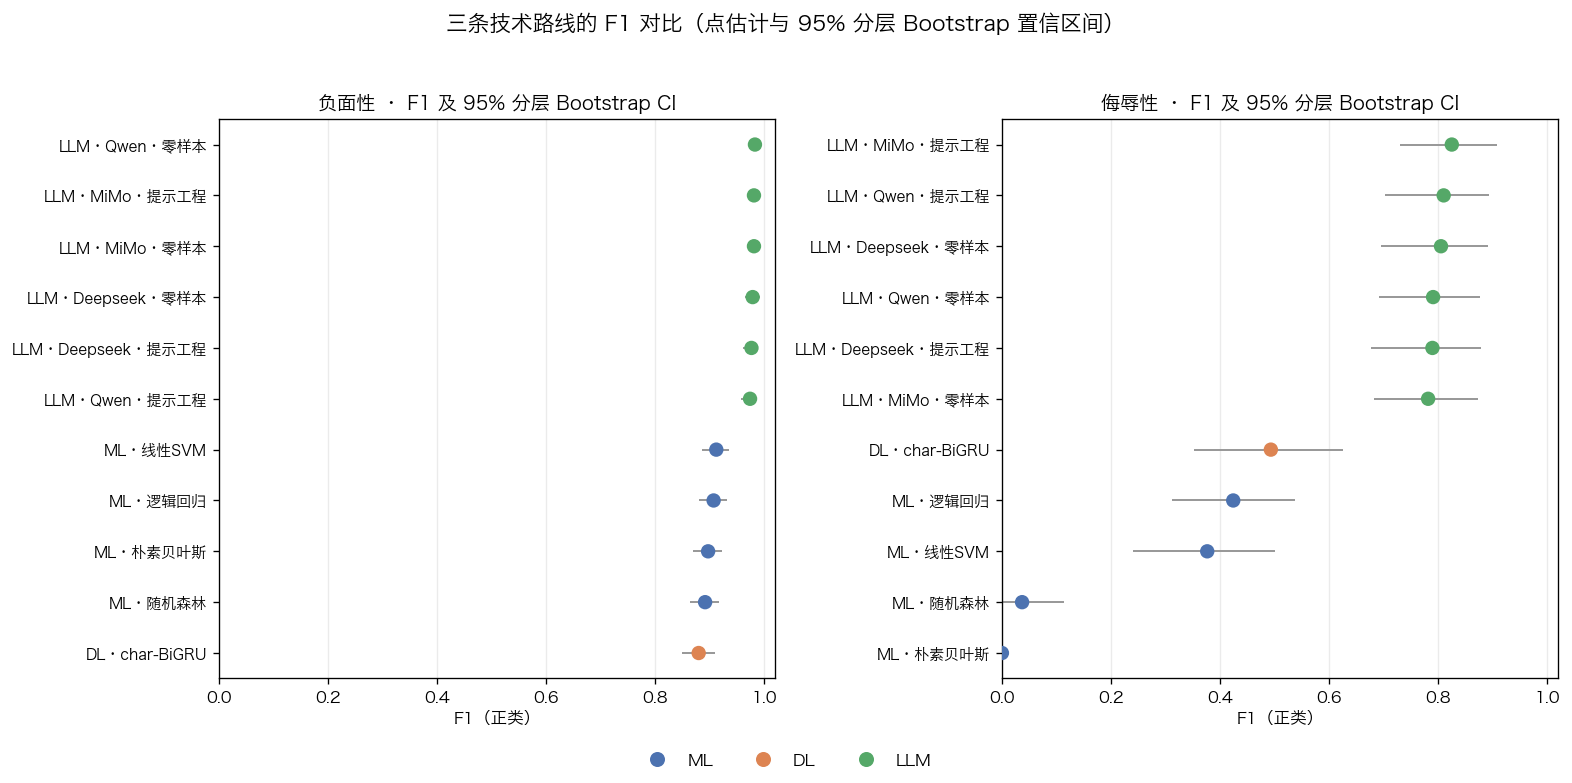

已保存 / saved: cmp_forest_f1.png

读图提示：置信区间有重叠 ≠ 差异不显著。CI 各自独立构造，
未使用配对信息；配对检验见 §8。


In [13]:
# ===== 7.3 主结果可视化：F1 森林图 / forest plot of F1 with 95% CI =====
fig, axes = plt.subplots(1, 2, figsize=(13.2, 6.4))
ROUTE_COLOR = {"ML": "#4C72B0", "DL": "#DD8452", "LLM": "#55A868"}

for ax, dim in zip(axes, DIMS):
    sub = main_df[main_df["维度"] == dim].sort_values("F1").reset_index(drop=True)
    ypos = np.arange(len(sub))
    colors = [ROUTE_COLOR[r] for r in sub["路线"]]
    ax.errorbar(sub["F1"], ypos,
                xerr=[sub["F1"] - sub["F1_lo"], sub["F1_hi"] - sub["F1"]],
                fmt="o", ecolor="#999999", elinewidth=1.2, capsize=3,
                markersize=7, markerfacecolor="none", markeredgewidth=0)
    ax.scatter(sub["F1"], ypos, c=colors, s=58, zorder=3)
    ax.set_yticks(ypos); ax.set_yticklabels(sub["方法"], fontsize=9)
    ax.set_xlabel("F1（正类）")
    ax.set_title(f"{dim} · F1 及 95% 分层 Bootstrap CI", fontsize=11.5)
    ax.grid(axis="x", alpha=0.25)
    ax.set_xlim(0, 1.02)
    # 退化基线：全判 0 的 F1 = 0；此处标注正类占比供参照
    ax.axvline(0, color="#cccccc", lw=1)

handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k, markersize=8)
           for k, c in ROUTE_COLOR.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=10)
fig.suptitle("三条技术路线的 F1 对比（点估计与 95% 分层 Bootstrap 置信区间）", fontsize=13, y=1.0)
plt.tight_layout(rect=[0, 0.045, 1, 0.97])
plt.savefig(OUT_DIR / "cmp_forest_f1.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close("all")
print("已保存 / saved: cmp_forest_f1.png")
print("""
读图提示：置信区间有重叠 ≠ 差异不显著。CI 各自独立构造，
未使用配对信息；配对检验见 §8。""")


---

## 8. 统计推断

### 8.1 三个层次的检验

| 层次 | 方法 | 回答的问题 |
|---|---|---|
| 全局 | **Cochran's Q** | k 个方法在同一样本上的对错模式，整体上是否同质？ |
| 两两 | **McNemar 精确检验** | 方法 A 与 B 在哪些样本上一个对一个错？差异是否超出偶然？ |
| 效应 | **ΔF1 的配对 Bootstrap CI** + **优势比 OR** | 差异有多大？区间是否跨过 0？ |
| 精度 | **最小可检测差异 MDES**（§8.5） | 这个样本量本来能测出多大的差异？ |

### 8.2 为什么用配对检验

所有方法都在**同一批 420 条样本**上评估，样本难度是共同因素。
非配对检验（如两个独立比例的 z 检验）会把样本难度差异计入误差，严重低估检验力。
McNemar 只关注**不一致的配对**（A 对 B 错 / A 错 B 对），把共同对错的部分剔除。

### 8.3 多重比较校正

11 个方法两两比较共 C(11,2) = 55 对，每个维度各一组。
若不做校正，在 α=0.05 下平均会有 2.75 个"显著"结果纯属偶然。
本 notebook 采用 **Holm–Bonferroni step-down**（比 Bonferroni 更有检验力，
同时严格控制 family-wise error rate）。校正**在每个维度内部**进行。

### 8.4 ΔF1 的置信区间为什么必须配对

ΔF1 的分布不能用两个独立 CI 相减得到。本 notebook 用**同一套分层 Bootstrap 索引**
同时计算两个方法的 F1，再取差值，得到 ΔF1 的抽样分布与 95% CI。
这样得到的区间若不含 0，才与 McNemar 的结论可互相印证。

In [14]:
# ===== 8.1 全局检验：Cochran's Q / omnibus test per dimension =====
NAMES = list(METHODS.keys())
Q_ROWS = []
for k, dim in enumerate(DIMS):
    P = np.stack([METHODS[nm]["pred"][:, k] for nm in NAMES])   # (k_methods, N)
    Q, df, p = cochran_q(P, Y[:, k])
    Q_ROWS.append({"维度": dim, "方法数": len(NAMES), "Cochran_Q": round(Q, 3),
                   "df": df, "p值": f"{p:.3e}" if p < 1e-3 else f"{p:.4f}",
                   "结论": "方法间存在整体差异" if p < ALPHA else "无法拒绝同质假设"})
    print(f"【{dim}】k={len(NAMES)}  Cochran's Q = {Q:.3f}, df = {df}, p = {p:.3e}")
    print(f"    → {'拒绝' if p < ALPHA else '无法拒绝'}「所有方法能力同质」的原假设\n")

q_df = pd.DataFrame(Q_ROWS)
print(q_df.to_string(index=False))
print("""
注意：Cochran's Q 是全局检验，只能告诉你"至少有一对方法不同"，不指出是哪一对。
具体差异由下面的两两 McNemar 检验给出。""")


【负面性】k=11  Cochran's Q = 229.246, df = 10, p = 1.236e-43
    → 拒绝「所有方法能力同质」的原假设

【侮辱性】k=11  Cochran's Q = 191.084, df = 10, p = 1.163e-35
    → 拒绝「所有方法能力同质」的原假设

 维度  方法数  Cochran_Q  df        p值        结论
负面性   11    229.246  10 1.236e-43 方法间存在整体差异
侮辱性   11    191.084  10 1.163e-35 方法间存在整体差异

注意：Cochran's Q 是全局检验，只能告诉你"至少有一对方法不同"，不指出是哪一对。
具体差异由下面的两两 McNemar 检验给出。


In [15]:
# ===== 8.2 两两 McNemar 精确检验 + Holm–Bonferroni 校正 =====
PAIR_ROWS = []
for k, dim in enumerate(DIMS):
    pairs, pvals = [], []
    for a, b in combinations(NAMES, 2):
        b01, b10, or_, p = mcnemar_exact(Y[:, k], METHODS[a]["pred"][:, k], METHODS[b]["pred"][:, k])
        pairs.append({"维度": dim, "方法A": a, "方法B": b,
                      "A错B对": b01, "A对B错": b10, "不一致对数": b01 + b10,
                      "优势比OR": (round(or_, 3) if np.isfinite(or_) else np.inf), "p_raw": p})
        pvals.append(p)
    adj = holm_bonferroni(pvals)
    for rec, pa in zip(pairs, adj):
        rec["p_Holm"] = pa
        rec["显著"] = "是" if pa < ALPHA else "否"
    PAIR_ROWS.extend(pairs)

pair_df = pd.DataFrame(PAIR_ROWS)

for dim in DIMS:
    sub = pair_df[pair_df["维度"] == dim]
    sig = sub[sub["显著"] == "是"].sort_values("p_Holm")
    print("=" * 96)
    print(f"【{dim}】共 {len(sub)} 对比较，Holm 校正后显著 {len(sig)} 对")
    print("=" * 96)
    if len(sig):
        print(sig[["方法A", "方法B", "A对B错", "A错B对", "优势比OR", "p_raw", "p_Holm"]]
              .to_string(index=False))
    else:
        print("  无任何一对在 Holm 校正后达到显著。")
    print()

print("""
【如何读优势比 OR】
OR = 「A 错 B 对」的样本数 / 「A 对 B 错」的样本数。
  OR  > 1  → B 在 A 失败的地方成功得更多，即 **B 优于 A**
  OR  < 1  → A 优于 B
  OR  = ∞  → A 的错误样本 B 全部答对，且 B 没有 A 能答对的独有样本（差异极大但样本少）
注意：OR 可以很大而 p 仍不显著——当不一致对数很少时，几个样本的翻转就能造出大 OR。
因此**必须与 p 值和 ΔF1 的 CI 一起看**。""")


【负面性】共 55 对比较，Holm 校正后显著 30 对
          方法A               方法B  A对B错  A错B对  优势比OR        p_raw       p_Holm
DL·char-BiGRU      LLM·Qwen·零样本     5    53 10.600 3.496477e-11 1.923062e-09
DL·char-BiGRU     LLM·MiMo·提示工程     5    52 10.400 6.401865e-11 3.457007e-09
DL·char-BiGRU      LLM·MiMo·零样本     5    52 10.400 6.401865e-11 3.457007e-09
DL·char-BiGRU  LLM·Deepseek·零样本     6    52  8.667 3.158190e-10 1.642259e-08
      ML·随机森林     LLM·MiMo·提示工程     5    49  9.800 3.891388e-10 1.984608e-08
      ML·随机森林      LLM·MiMo·零样本     5    49  9.800 3.891388e-10 1.984608e-08
      ML·随机森林      LLM·Qwen·零样本     6    51  8.500 5.676193e-10 2.781335e-08
DL·char-BiGRU LLM·Deepseek·提示工程     7    52  7.429 1.358992e-09 6.523161e-08
     ML·朴素贝叶斯      LLM·MiMo·零样本     5    46  9.200 2.328015e-09 1.094167e-07
     ML·朴素贝叶斯     LLM·MiMo·提示工程     5    46  9.200 2.328015e-09 1.094167e-07
     ML·朴素贝叶斯      LLM·Qwen·零样本     6    48  8.000 3.256530e-09 1.465439e-07
      ML·随机森林  LLM·Deepseek·零样本     7    50  7

In [16]:
# ===== 8.3 ΔF1 的配对 Bootstrap 置信区间 =====
# 用同一套分层索引计算两个方法的 F1，再取差值 —— 配对结构被完整保留。
DELTA_ROWS = []
F1_BOOT = {}          # (方法, 维度) -> (B,) 的 F1 分布，供后续复用
for k, dim in enumerate(DIMS):
    for nm in NAMES:
        F1_BOOT[(nm, dim)] = boot_metrics_from_index(Y[:, k], METHODS[nm]["pred"][:, k],
                                                     BOOT_IDX[dim])["F1"]
    for a, b in combinations(NAMES, 2):
        d = F1_BOOT[(b, dim)] - F1_BOOT[(a, dim)]      # ΔF1 = F1(B) - F1(A)
        lo, hi = np.percentile(d, [2.5, 97.5])
        pt_a = metrics_point(Y[:, k], METHODS[a]["pred"][:, k])["F1"]
        pt_b = metrics_point(Y[:, k], METHODS[b]["pred"][:, k])["F1"]
        DELTA_ROWS.append({"维度": dim, "方法A": a, "方法B": b,
                           "F1_A": round(pt_a, 4), "F1_B": round(pt_b, 4),
                           "ΔF1(B-A)": round(pt_b - pt_a, 4),
                           "ΔF1_lo": round(float(lo), 4), "ΔF1_hi": round(float(hi), 4),
                           "CI跨0": "是" if (lo <= 0 <= hi) else "否"})
delta_df = pd.DataFrame(DELTA_ROWS)

for dim in DIMS:
    sub = delta_df[(delta_df["维度"] == dim) & (delta_df["CI跨0"] == "否")]
    print("=" * 96)
    print(f"【{dim}】ΔF1 的 95% 配对 Bootstrap CI 不跨 0 的比较（{len(sub)} / "
          f"{len(delta_df[delta_df['维度']==dim])} 对）")
    print("=" * 96)
    if len(sub):
        s = sub.reindex(sub["ΔF1(B-A)"].abs().sort_values(ascending=False).index)
        print(s[["方法A", "方法B", "F1_A", "F1_B", "ΔF1(B-A)", "ΔF1_lo", "ΔF1_hi"]]
              .to_string(index=False))
    else:
        print("  没有任何一对的 ΔF1 置信区间排除 0。")
    print()
print("""
说明：ΔF1 的配对 Bootstrap CI 与 McNemar 的结论可能不完全一致。
原因在于两者衡量的是不同侧面：ΔF1 反映整体判别质量，McNemar 只看逐样本的对错翻转。
当两者冲突时，应以 McNemar（配对、非参数、不依赖 F1 的连续性）为主，
把 ΔF1 区间作为效应大小的补充描述。""")


【负面性】ΔF1 的 95% 配对 Bootstrap CI 不跨 0 的比较（32 / 55 对）
          方法A               方法B   F1_A   F1_B  ΔF1(B-A)  ΔF1_lo  ΔF1_hi
DL·char-BiGRU      LLM·Qwen·零样本 0.8798 0.9830    0.1032  0.0724  0.1352
DL·char-BiGRU      LLM·MiMo·零样本 0.8798 0.9812    0.1014  0.0722  0.1332
DL·char-BiGRU     LLM·MiMo·提示工程 0.8798 0.9812    0.1014  0.0718  0.1339
DL·char-BiGRU  LLM·Deepseek·零样本 0.8798 0.9788    0.0990  0.0680  0.1311
DL·char-BiGRU LLM·Deepseek·提示工程 0.8798 0.9766    0.0968  0.0659  0.1282
DL·char-BiGRU     LLM·Qwen·提示工程 0.8798 0.9740    0.0942  0.0608  0.1280
      ML·随机森林      LLM·Qwen·零样本 0.8916 0.9830    0.0914  0.0632  0.1208
      ML·随机森林      LLM·MiMo·零样本 0.8916 0.9812    0.0896  0.0628  0.1176
      ML·随机森林     LLM·MiMo·提示工程 0.8916 0.9812    0.0896  0.0624  0.1179
      ML·随机森林  LLM·Deepseek·零样本 0.8916 0.9788    0.0872  0.0583  0.1160
     ML·朴素贝叶斯      LLM·Qwen·零样本 0.8971 0.9830    0.0859  0.0578  0.1144
      ML·随机森林 LLM·Deepseek·提示工程 0.8916 0.9766    0.0850  0.0564  0.1140
     ML·朴素贝叶斯

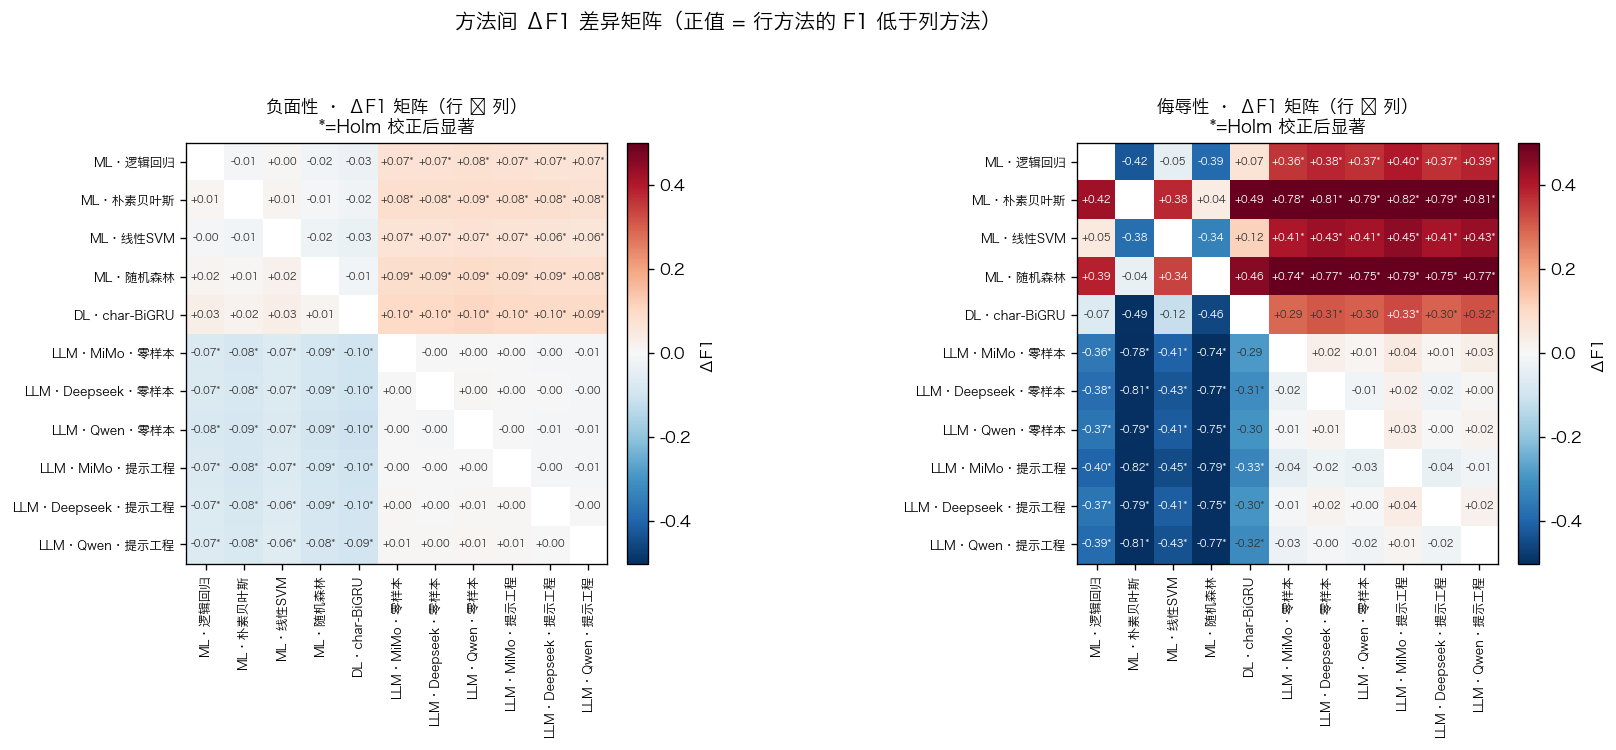

已保存 / saved: cmp_delta_f1_matrix.png


In [17]:
# ===== 8.4 显著性矩阵与效应量可视化 / significance matrix =====
fig, axes = plt.subplots(1, 2, figsize=(15.0, 6.2))
for ax, dim in zip(axes, DIMS):
    sub = pair_df[pair_df["维度"] == dim]
    mat = pd.DataFrame(np.nan, index=NAMES, columns=NAMES)
    ormat = pd.DataFrame(np.nan, index=NAMES, columns=NAMES)
    for _, r in sub.iterrows():
        # 用 ΔF1 作为方向性效应量（比 OR 更直观），显著性用 Holm 校正后的 p
        d = delta_df[(delta_df["维度"] == dim) & (delta_df["方法A"] == r["方法A"]) &
                     (delta_df["方法B"] == r["方法B"])]
        dv = d["ΔF1(B-A)"].iloc[0] if len(d) else 0.0
        mat.loc[r["方法A"], r["方法B"]] = dv
        mat.loc[r["方法B"], r["方法A"]] = -dv
        # 存 0/1 而非 bool，避免 pandas 3.0 对 float 列写入 bool 的严格校验
        sig01 = float(r["p_Holm"] < ALPHA)
        ormat.loc[r["方法A"], r["方法B"]] = sig01
        ormat.loc[r["方法B"], r["方法A"]] = sig01

    im = ax.imshow(mat.values, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
    ax.set_xticks(range(len(NAMES))); ax.set_xticklabels(NAMES, rotation=90, fontsize=7.5)
    ax.set_yticks(range(len(NAMES))); ax.set_yticklabels(NAMES, fontsize=7.5)
    for i in range(len(NAMES)):
        for j in range(len(NAMES)):
            if i == j:
                continue
            v = mat.values[i, j]
            if np.isnan(v):
                continue
            star = "*" if ormat.values[i, j] else ""
            ax.text(j, i, f"{v:+.2f}{star}", ha="center", va="center", fontsize=6.2,
                    color="white" if abs(v) > 0.32 else "#333333")
    ax.set_title(f"{dim} · ΔF1 矩阵（行 − 列）\n*=Holm 校正后显著", fontsize=10.5)
    fig.colorbar(im, ax=ax, fraction=0.042, pad=0.03, label="ΔF1")

fig.suptitle("方法间 ΔF1 差异矩阵（正值 = 行方法的 F1 低于列方法）", fontsize=12.5, y=1.0)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(OUT_DIR / "cmp_delta_f1_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close("all")
print("已保存 / saved: cmp_delta_f1_matrix.png")


### 8.5 检验力与最小可检测差异（power / MDES）

"p > 0.05"只能说明"没有足够证据"，不能说明"没有差异"。
在小样本研究里，后者是更常见的误读。因此必须回答：

> 以当前的样本量和不一致对数量，这个检验**本来能**检测出多大的差异？

对 McNemar 精确检验，检验力完全由**不一致对数** $n_d$ 决定：
在显著性水平 α、检验力 1−β 下，可检测的最小效应是使
$\mathrm{Binom}(n_d,\, 0.5+\delta)$ 的尾部概率达到临界值的最小 $\delta$。
$\delta$ 的含义是"不一致对中偏向一方的比例超出 50% 的幅度"。

同时报告 ΔF1 的 95% CI 半宽中位数——这是另一个视角下的精度指标，
更贴近实际关心的问题："这个样本量能把 F1 的差异定位到多细？"

In [18]:
# ===== 8.5 检验力与最小可检测差异 / power analysis =====
def mcnemar_mdes(n_disc, alpha=ALPHA, power=0.80):
    """
    给定不一致对数 n_disc，返回在指定 alpha/power 下可检测的最小效应 delta。
    delta = 不一致对中占优一方的比例 - 0.5。

    精确 McNemar 的拒绝域在**上尾**：需要 b01 达到临界值 k*。
    （注意不能用「找到第一个 p<alpha 的 k」——那样 k=0 就会满足，
      因为 0 次成功同样是极端偏离，得到的是下尾临界值。）
    """
    from scipy.stats import binom
    if n_disc < 1:
        return np.nan, np.nan
    # 上尾临界值：最小的 k 使得 P(X >= k | p=0.5) < alpha
    k_star = None
    for kk in range(1, n_disc + 1):
        if binom.sf(kk - 1, n_disc, 0.5) < alpha:
            k_star = kk
            break
    if k_star is None:
        return np.nan, np.nan          # 样本量太小，任何结果都不可能显著
    for delta in np.arange(0.005, 0.50, 0.005):
        p1 = 0.5 + delta
        pw = float(binom.sf(k_star - 1, n_disc, p1))
        if pw >= power:
            return float(delta), float(pw)
    return np.nan, np.nan


POWER_ROWS = []
for dim in DIMS:
    sub = pair_df[pair_df["维度"] == dim]
    med_disc = float(sub["不一致对数"].median())
    min_disc = float(sub["不一致对数"].min())
    mean_disc = float(sub["不一致对数"].mean())
    d_med, _ = mcnemar_mdes(int(round(med_disc)))
    d_min, _ = mcnemar_mdes(int(round(min_disc)))
    dd = delta_df[delta_df["维度"] == dim]
    half = float(((dd["ΔF1_hi"] - dd["ΔF1_lo"]) / 2).median())
    POWER_ROWS.append({
        "维度": dim,
        "不一致对数_中位": med_disc,
        "不一致对数_最少": min_disc,
        "MDES_δ(中位)": round(d_med, 3) if not np.isnan(d_med) else np.nan,
        "MDES_δ(最少)": round(d_min, 3) if not np.isnan(d_min) else np.nan,
        "需翻转对数(中位)": round(d_med * med_disc, 1) if not np.isnan(d_med) else np.nan,
        "ΔF1_CI半宽_中位": round(half, 4),
    })
power_df = pd.DataFrame(POWER_ROWS)
print("【检验力分析 / power analysis】")
print(power_df.to_string(index=False))

_half_neg = float(power_df[power_df["维度"] == "负面性"]["ΔF1_CI半宽_中位"].iloc[0])
_half_ins = float(power_df[power_df["维度"] == "侮辱性"]["ΔF1_CI半宽_中位"].iloc[0])
print(f"""
判读：
- 检验力设定 1−β = 0.80，双侧 α = 0.05；δ = 占优方在不一致对中超出 50% 的比例。
- 「MDES_δ(中位)」是在不一致对数达到中位水平时能可靠检出的最小效应；
  「MDES_δ(最少)」对应最不利的方法对，属于保守下界。
- 「需翻转对数」把 δ 换算成具体样本数，更容易感受：
  即"至少要有这么多条样本在同一方向上翻转，检验才能达到 80% 的检出概率"。
- 「ΔF1_CI半宽_中位」给出另一个视角的精度：当前数据能把 F1 差异定位到多细。

结论：
  负面性维度：ΔF1 的置信区间半宽中位数约 {_half_neg:.3f}，
    因此**小于约 {_half_neg:.3f} 的 F1 差距在本数据上无法分辨方向**；
  侮辱性维度：半宽中位数约 {_half_ins:.3f}，
    精度明显更差，**小于约 {_half_ins:.3f} 的差距不应被解释为方法优劣**。

  这正是侮辱性正类只有 {int(Y[:,1].sum())} 条的代价——不是检验方法不够好，
  而是信息量本身不足。""")


【检验力分析 / power analysis】
 维度  不一致对数_中位  不一致对数_最少  MDES_δ(中位)  MDES_δ(最少)  需翻转对数(中位)  ΔF1_CI半宽_中位
负面性      46.0       2.0        0.20         NaN        9.2       0.0267
侮辱性      35.0       6.0        0.21       0.465        7.3       0.1123

判读：
- 检验力设定 1−β = 0.80，双侧 α = 0.05；δ = 占优方在不一致对中超出 50% 的比例。
- 「MDES_δ(中位)」是在不一致对数达到中位水平时能可靠检出的最小效应；
  「MDES_δ(最少)」对应最不利的方法对，属于保守下界。
- 「需翻转对数」把 δ 换算成具体样本数，更容易感受：
  即"至少要有这么多条样本在同一方向上翻转，检验才能达到 80% 的检出概率"。
- 「ΔF1_CI半宽_中位」给出另一个视角的精度：当前数据能把 F1 差异定位到多细。

结论：
  负面性维度：ΔF1 的置信区间半宽中位数约 0.027，
    因此**小于约 0.027 的 F1 差距在本数据上无法分辨方向**；
  侮辱性维度：半宽中位数约 0.112，
    精度明显更差，**小于约 0.112 的差距不应被解释为方法优劣**。

  这正是侮辱性正类只有 45 条的代价——不是检验方法不够好，
  而是信息量本身不足。


---

## 9. 分层分析

### 9.1 按类型分层：必须避开 Accuracy 陷阱

五个类型与标签高度嵌套：好评组负面性正类为 0，四个差评组接近 100%。
因此**同一张 Accuracy 表里混着两种方向相反的指标**：

- 好评组的 Accuracy = 特异度（判对了多少"不负面"）
- 差评组的 Accuracy = 灵敏度（检出了多少"负面"）

更严重的是，当某组正类极少时，Accuracy 会被负类稀释。
例如语气型差评共 73 条、其中侮辱性正类仅 6 条，
"无条件全判 0"的退化模型在该组的 Accuracy 高达 (73−6)/73 = **0.9178**——
一个没有任何判别能力的模型，在这一格反而拿到高分。

**正确做法**：按"该组内部该指标是否有方向性"拆分——

| 情形 | 应看的指标 |
|---|---|
| 组内正类数为 0（好评、正常差评的侮辱性） | **误报率**（该组有多少比例被误判为正） |
| 组内正类数 > 0（三个对抗组的侮辱性） | **组内召回率** |

按类型分层的另一重意义：三种对抗类型（谐音缩写 / 反讽 / 拆字符号）
对应三类不同的语言规避手段，方法间的能力差异极可能在这里分化，
而不是体现在总体 F1 上。

### 9.2 按文本长度分层

短评论信息量少，模型更依赖先验；长评论含更多证据但也可能被无关内容干扰。
按字符长度三分位切分，观察各方法的稳健性。

In [19]:
# ===== 9.1 按类型分层的组内召回与误报 / per-type recall & false-positive rate =====
TYPE_ROWS = []
for nm, v in METHODS.items():
    for k, dim in enumerate(DIMS):
        for t in TYPE_ORDER:
            msk = (human["类型"] == t).to_numpy()
            yt = Y[msk, k]; pt = v["pred"][msk, k]
            n_pos = int((yt == 1).sum()); n_neg = int((yt == 0).sum())
            TYPE_ROWS.append({
                "方法": nm, "路线": v["route"], "维度": dim, "类型": t,
                "n": int(msk.sum()), "正类数": n_pos, "负类数": n_neg,
                "组内召回": round(float((pt[yt == 1] == 1).mean()), 4) if n_pos else np.nan,
                "组内误报": round(float((pt[yt == 0] == 1).mean()), 4) if n_neg else np.nan,
                "组内Accuracy": round(float((yt == pt).mean()), 4),
            })
type_df = pd.DataFrame(TYPE_ROWS)

# --- 演示 Accuracy 陷阱：语气型差评的侮辱性 ---
_demo = human[human["类型"] == "语气型差评"]
_n, _npos = len(_demo), int(_demo["侮辱性标签"].sum())
print("=" * 96)
print("【陷阱演示】语气型差评 · 侮辱性：「全判 0」退化基线的 Accuracy")
print("=" * 96)
print(f"该组 n={_n}，侮辱性正类={_npos} → 一个无条件全判 0 的模型 Accuracy = "
      f"{(_n-_npos)/_n:.4f}")
sub = type_df[(type_df["类型"] == "语气型差评") & (type_df["维度"] == "侮辱性")]
print()
print(sub[["方法", "组内Accuracy", "组内召回", "组内误报"]].to_string(index=False))
print(f"""
要点：上表中 Accuracy 与召回率几乎背离——Accuracy ≥ {(_n-_npos)/_n:.4f} 只说明"没有大量误报"，
不说明"检出了侮辱"。真正反映能力的是「组内召回」列。
{'-' * 96}""")

# --- 三个对抗类型的侮辱性召回：唯一有判别力的格子 ---
ADV = ["声音型差评", "语气型差评", "视觉型差评"]
print("\n【核心分层表】侮辱性 · 三个对抗类型的组内召回（正类数决定可比性）")
piv = (type_df[(type_df["维度"] == "侮辱性") & (type_df["类型"].isin(ADV))]
       .pivot_table(index="方法", columns="类型", values="组内召回")
       .reindex(columns=ADV))
npos_map = type_df[type_df["类型"].isin(ADV)].groupby("类型")["正类数"].first()
piv.columns = [f"{c}（正类{npos_map[c]}）" for c in ADV]
print(piv.to_string())

print("\n【核心分层表】负面性 · 好评组误报率 与 正常差评组召回")
neg_fpr = (type_df[(type_df["维度"] == "负面性") & (type_df["类型"] == "好评")]
           .set_index("方法")["组内误报"].sort_values())
neg_rec = (type_df[(type_df["维度"] == "负面性") & (type_df["类型"] == "正常差评")]
           .set_index("方法")["组内召回"].sort_values(ascending=False))
print(pd.concat([neg_fpr.rename("好评组_误报率(越低越好)"),
                 neg_rec.rename("正常差评组_召回(越高越好)")], axis=1).to_string())


【陷阱演示】语气型差评 · 侮辱性：「全判 0」退化基线的 Accuracy
该组 n=73，侮辱性正类=6 → 一个无条件全判 0 的模型 Accuracy = 0.9178

               方法  组内Accuracy   组内召回   组内误报
          ML·逻辑回归      0.7123 0.6667 0.2836
         ML·朴素贝叶斯      0.9178 0.0000 0.0000
         ML·线性SVM      0.7534 0.5000 0.2239
          ML·随机森林      0.9178 0.0000 0.0000
    DL·char-BiGRU      0.8630 0.0000 0.0597
     LLM·MiMo·零样本      0.9041 0.3333 0.0448
 LLM·Deepseek·零样本      0.9041 0.0000 0.0149
     LLM·Qwen·零样本      0.9178 0.3333 0.0299
    LLM·MiMo·提示工程      0.9452 0.3333 0.0000
LLM·Deepseek·提示工程      0.9178 0.0000 0.0000
    LLM·Qwen·提示工程      0.9178 0.0000 0.0000

要点：上表中 Accuracy 与召回率几乎背离——Accuracy ≥ 0.9178 只说明"没有大量误报"，
不说明"检出了侮辱"。真正反映能力的是「组内召回」列。
------------------------------------------------------------------------------------------------

【核心分层表】侮辱性 · 三个对抗类型的组内召回（正类数决定可比性）
                   声音型差评（正类30）  语气型差评（正类73）  视觉型差评（正类21）
方法                                                      
DL·char-BiGRU           0.3636       0.0000      

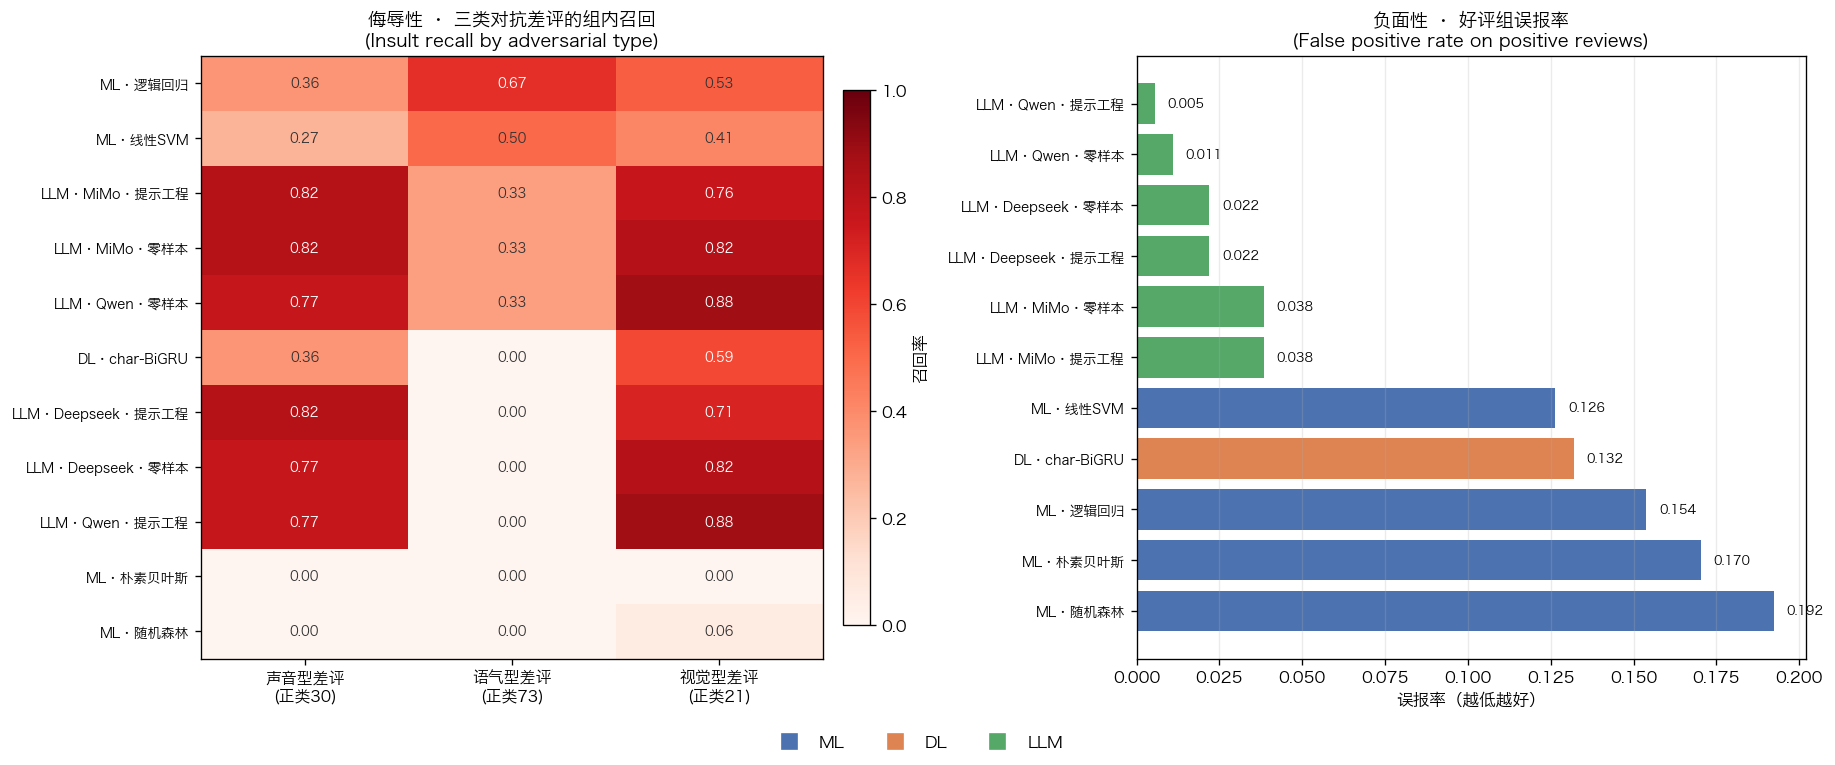

已保存 / saved: cmp_by_type.png


In [20]:
# ===== 9.1b 分层结果可视化 / per-type heatmap =====
fig, axes = plt.subplots(1, 2, figsize=(15.4, 6.6))

# 左：侮辱性 · 三个对抗类型的召回
ax = axes[0]
piv = (type_df[(type_df["维度"] == "侮辱性") & (type_df["类型"].isin(ADV))]
       .pivot_table(index="方法", columns="类型", values="组内召回").reindex(columns=ADV))
piv = piv.sort_values("语气型差评", ascending=False)
im = ax.imshow(piv.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(ADV)))
ax.set_xticklabels([f"{c}\n(正类{npos_map[c]})" for c in ADV], fontsize=9.5)
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index, fontsize=8.2)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, "—" if np.isnan(v) else f"{v:.2f}", ha="center", va="center",
                fontsize=8, color="white" if (not np.isnan(v) and v > 0.55) else "#333333")
ax.set_title("侮辱性 · 三类对抗差评的组内召回\n(Insult recall by adversarial type)", fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03, label="召回率")

# 右：负面性 · 好评组误报率
ax = axes[1]
fpr = (type_df[(type_df["维度"] == "负面性") & (type_df["类型"] == "好评")]
       .set_index("方法")["组内误报"].sort_values())
colors = [ROUTE_COLOR[METHODS[i]["route"]] for i in fpr.index]
ax.barh(np.arange(len(fpr)), fpr.values, color=colors)
ax.set_yticks(np.arange(len(fpr))); ax.set_yticklabels(fpr.index, fontsize=8.2)
ax.invert_yaxis()
ax.set_xlabel("误报率（越低越好）")
ax.set_title("负面性 · 好评组误报率\n(False positive rate on positive reviews)", fontsize=11)
for i, v in enumerate(fpr.values):
    ax.text(v + fpr.max() * 0.02, i, f"{v:.3f}", va="center", fontsize=7.8)
ax.grid(axis="x", alpha=0.25)

handles = [plt.Line2D([], [], marker="s", ls="", color=c, label=k, markersize=9)
           for k, c in ROUTE_COLOR.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=10)
plt.tight_layout(rect=[0, 0.045, 1, 0.97])
plt.savefig(OUT_DIR / "cmp_by_type.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close("all")
print("已保存 / saved: cmp_by_type.png")


In [21]:
# ===== 9.2 按文本长度分层 / length-stratified analysis =====
lengths = TEXT.str.len().to_numpy()
q1, q2 = np.percentile(lengths, [33.33, 66.67])
def len_bucket(x):
    return "短(≤%d字)" % int(q1) if x <= q1 else ("中" if x <= q2 else "长(>%d字)" % int(q2))
BUCKETS = np.array([len_bucket(x) for x in lengths])
BUCKET_ORDER = [f"短(≤{int(q1)}字)", "中", f"长(>{int(q2)}字)"]

print(f"长度三分位：Q33={q1:.0f} 字，Q67={q2:.0f} 字")
print("各桶样本数:", dict(pd.Series(BUCKETS).value_counts().reindex(BUCKET_ORDER).items()))
print("各桶正类数（侮辱性）:",
      {b: int(Y[BUCKETS == b, 1].sum()) for b in BUCKET_ORDER})

LEN_ROWS = []
for nm, v in METHODS.items():
    for k, dim in enumerate(DIMS):
        for b in BUCKET_ORDER:
            msk = BUCKETS == b
            yt = Y[msk, k]; pt = v["pred"][msk, k]
            n_pos = int((yt == 1).sum())
            LEN_ROWS.append({"方法": nm, "路线": v["route"], "维度": dim, "长度桶": b,
                             "n": int(msk.sum()), "正类数": n_pos,
                             "召回": round(float((pt[yt == 1] == 1).mean()), 4) if n_pos else np.nan,
                             "误报": round(float((pt[yt == 0] == 1).mean()), 4)
                                     if (yt == 0).sum() else np.nan})
len_df = pd.DataFrame(LEN_ROWS)

for dim in DIMS:
    print(f"\n【{dim} · 按长度分层：召回率】")
    piv = (len_df[len_df["维度"] == dim].pivot_table(index="方法", columns="长度桶",
                                                     values="召回").reindex(columns=BUCKET_ORDER))
    print(piv.to_string())
print("""
注意：长度桶内的正类数差异很大，短文本桶的侮辱性正类可能只有个位数，
单看某一格容易过读；此处主要用于观察**趋势方向**而非下结论。""")


长度三分位：Q33=18 字，Q67=36 字
各桶样本数: {'短(≤18字)': 150, '中': 132, '长(>36字)': 138}
各桶正类数（侮辱性）: {'短(≤18字)': 13, '中': 18, '长(>36字)': 14}

【负面性 · 按长度分层：召回率】
长度桶                短(≤18字)       中  长(>36字)
方法                                         
DL·char-BiGRU       0.8125  0.8902   0.9054
LLM·Deepseek·提示工程   0.9625  0.9634   1.0000
LLM·Deepseek·零样本    0.9750  0.9634   1.0000
LLM·MiMo·提示工程       1.0000  0.9878   1.0000
LLM·MiMo·零样本        0.9875  1.0000   1.0000
LLM·Qwen·提示工程       0.9375  0.9268   1.0000
LLM·Qwen·零样本        0.9875  0.9512   1.0000
ML·朴素贝叶斯            0.8750  0.9390   0.9595
ML·线性SVM            0.8750  0.9390   0.9595
ML·逻辑回归             0.8875  0.9512   0.9595
ML·随机森林             0.9250  0.9390   0.9054

【侮辱性 · 按长度分层：召回率】
长度桶                短(≤18字)       中  长(>36字)
方法                                         
DL·char-BiGRU       0.3846  0.4444   0.3571
LLM·Deepseek·提示工程   0.6154  0.7222   0.6429
LLM·Deepseek·零样本    0.6154  0.8333   0.5714
LLM·MiMo·提示工程       0.6154  0.7778   0.7857


---

## 10. 错误结构分析

总体 F1 只能告诉你"谁更强"，无法告诉你"为什么"。
本节考察一个更有信息量的问题：

> **不同技术路线的错误是重合的，还是互补的？**

如果三条路线在**同一批样本**上犯错，说明这些样本对当前所有技术都是共同难点，
提升空间在数据与任务定义；如果各自犯不同的错，则说明技术路线存在互补性，
模型融合有实用价值。

做法：从每条路线中选出代表方法（ML 选 F1 最高者、DL 取集成、LLM 选 F1 最高者），
把每个样本的 2³ = 8 种"对错组合"统计出来。

In [22]:
# ===== 10.1 三条路线的代表方法与错误重叠 / error overlap across routes =====
def best_of(route, dim):
    cand = [(nm, metrics_point(Y[:, DIMS.index(dim)], v["pred"][:, DIMS.index(dim)])["F1"])
            for nm, v in METHODS.items() if v["route"] == route]
    return max(cand, key=lambda x: x[1])

OVERLAP_SUMMARY = []
for dim in DIMS:
    k = DIMS.index(dim)
    reps = {r: best_of(r, dim) for r in ["ML", "DL", "LLM"]}
    print("=" * 96)
    print(f"【{dim}】代表方法： " + " | ".join(f"{r}→{nm}（F1={f1:.4f}）"
                                              for r, (nm, f1) in reps.items()))
    print("=" * 96)

    correct = {}
    for r, (nm, _) in reps.items():
        correct[r] = (METHODS[nm]["pred"][:, k] == Y[:, k])

    rows = []
    for combo in [(True, True, True), (True, True, False), (True, False, True),
                  (False, True, True), (True, False, False), (False, True, False),
                  (False, False, True), (False, False, False)]:
        msk = (correct["ML"] == combo[0]) & (correct["DL"] == combo[1]) & (correct["LLM"] == combo[2])
        rows.append({"ML": "✔" if combo[0] else "✘",
                     "DL": "✔" if combo[1] else "✘",
                     "LLM": "✔" if combo[2] else "✘",
                     "样本数": int(msk.sum()),
                     "占比": f"{msk.mean():.1%}"})
    ov = pd.DataFrame(rows)
    print(ov.to_string(index=False))

    n_all_correct = int(((correct["ML"]) & (correct["DL"]) & (correct["LLM"])).sum())
    n_all_wrong = int(((~correct["ML"]) & (~correct["DL"]) & (~correct["LLM"])).sum())
    n_any_uniq = int(sum(1 for i in range(N)
                         if sum([correct["ML"][i], correct["DL"][i], correct["LLM"][i]]) == 1))
    print(f"""
  三条路线全部判对     : {n_all_correct:>3d} / {N}（{n_all_correct/N:.1%}）
  三条路线全部判错     : {n_all_wrong:>3d} / {N}（{n_all_wrong/N:.1%}）← 共同盲区
  只有一条路线判对     : {n_any_uniq:>3d} / {N}（{n_any_uniq/N:.1%}）← 互补性证据""")
    OVERLAP_SUMMARY.append({"维度": dim, "代表_ML": reps["ML"][0], "代表_DL": reps["DL"][0],
                            "代表_LLM": reps["LLM"][0], "全部判对": n_all_correct,
                            "全部判错": n_all_wrong, "仅一条判对": n_any_uniq})
    print()
overlap_df = pd.DataFrame(OVERLAP_SUMMARY)


【负面性】代表方法： ML→ML·线性SVM（F1=0.9121） | DL→DL·char-BiGRU（F1=0.8798） | LLM→LLM·Qwen·零样本（F1=0.9830）
ML DL LLM  样本数    占比
 ✔  ✔   ✔  342 81.4%
 ✔  ✔   ✘    4  1.0%
 ✔  ✘   ✔   31  7.4%
 ✘  ✔   ✔   17  4.0%
 ✔  ✘   ✘    1  0.2%
 ✘  ✔   ✘    1  0.2%
 ✘  ✘   ✔   22  5.2%
 ✘  ✘   ✘    2  0.5%

  三条路线全部判对     : 342 / 420（81.4%）
  三条路线全部判错     :   2 / 420（0.5%）← 共同盲区
  只有一条路线判对     :  24 / 420（5.7%）← 互补性证据

【侮辱性】代表方法： ML→ML·逻辑回归（F1=0.4242） | DL→DL·char-BiGRU（F1=0.4932） | LLM→LLM·MiMo·提示工程（F1=0.8250）
ML DL LLM  样本数    占比
 ✔  ✔   ✔  344 81.9%
 ✔  ✔   ✘    4  1.0%
 ✔  ✘   ✔   13  3.1%
 ✘  ✔   ✔   34  8.1%
 ✔  ✘   ✘    2  0.5%
 ✘  ✔   ✘    1  0.2%
 ✘  ✘   ✔   15  3.6%
 ✘  ✘   ✘    7  1.7%

  三条路线全部判对     : 344 / 420（81.9%）
  三条路线全部判错     :   7 / 420（1.7%）← 共同盲区
  只有一条路线判对     :  18 / 420（4.3%）← 互补性证据



In [23]:
# ===== 10.2 共同盲区的典型样本 / common failure cases =====
for dim in DIMS:
    k = DIMS.index(dim)
    reps = {r: best_of(r, dim) for r in ["ML", "DL", "LLM"]}
    wrong_all = np.ones(N, dtype=bool)
    for r, (nm, _) in reps.items():
        wrong_all &= (METHODS[nm]["pred"][:, k] != Y[:, k])
    idx = np.where(wrong_all)[0]
    print("=" * 96)
    print(f"【{dim}】三条路线共同判错的样本（{len(idx)} 条）")
    print("=" * 96)
    if len(idx) == 0:
        print("  无。")
        continue
    show = pd.DataFrame({
        "行号": idx,
        "类型": human.loc[idx, "类型"].to_numpy(),
        "真值": Y[idx, k],
        "ML": METHODS[reps['ML'][0]]["pred"][idx, k],
        "DL": METHODS[reps['DL'][0]]["pred"][idx, k],
        "LLM": METHODS[reps['LLM'][0]]["pred"][idx, k],
        "评论": [t[:52] + ("…" if len(t) > 52 else "") for t in TEXT.iloc[idx]],
    })
    print(show.to_string(index=False))
    print()


【负面性】三条路线共同判错的样本（2 条）
 行号   类型  真值  ML  DL  LLM                                                    评论
189 正常差评   1   0   0    0                        他们家食材挺新鲜的 好吃的 份量也不错 说不要辣 就一点la
205 正常差评   0   1   1    1 这样吃完你们觉得好不好吃？这是我第二次来这家吃了，味道不错跟我们老家一样，但是我感觉这次的面有点少了感觉…

【侮辱性】三条路线共同判错的样本（7 条）
 行号    类型  真值  ML  DL  LLM                                                    评论
 22 语气型差评   1   0   0    0 完美避开了所有好吃的可能，在“不让人吃”的领域里自成一派，能把每道菜都做得精准地避开八大菜系的任何一种味…
 28 语气型差评   1   0   0    0                      吃完当天晚上就去cos喷射战士，这通便效果简直比什么开塞露都管用
 77 声音型差评   1   0   0    0                            广告推流真的强，实际上全都在tree new bee
 91 声音型差评   1   0   0    0                                              鱼闻起来和4一样
 94 声音型差评   1   0   0    0                                         你炒的是肥肠还是达芬？？？
102 视觉型差评   1   0   0    0                                       这家的菜，以后我再点我就是傻福
119 视觉型差评   1   0   0    0                                    这饭菜的味道，门臽王爷吃了都连夜逃跑



---

## 11. 敏感性分析

任何单一分析流程都可能被质疑"结论是不是取决于某个设定"。
本节系统地改变设定，检验主结论是否稳健。

| 编号 | 扰动 | 要回答的质疑 |
|---|---|---|
| 11.1 | 去除重复文本（仅保留首次出现） | 结论是否依赖重复样本？ |
| 11.2 | 仅保留 4 位标注员完全一致的样本 | 结论是否由标注噪声驱动？ |
| 11.3 | DL 的 5 个随机种子逐一计算 | DL 的差距是否在种子波动范围内？ |
| 11.4 | 加入层级后处理（侮辱 ⇒ 负面） | 后处理是否改变结论？ |
| 11.5 | 阈值扫描（精确率–召回率轨迹） | 若允许调阈值，ML/DL 能否追平 LLM？ |
| 11.6 | 提示模式的配对检验 | 提示词工程是否带来可靠增益？ |

In [24]:
# ===== 11.1 / 11.2 子集重估 / re-estimation on data subsets =====
# --- 子集 A：去重（每个归一化文本仅保留第一个出现） ---
_, first_idx = np.unique(GROUPS, return_index=True)
UNIQ_MASK = np.zeros(N, dtype=bool); UNIQ_MASK[np.sort(first_idx)] = True

# --- 子集 B：四位标注员完全一致 ---
unanimous_mask = np.ones(N, dtype=bool)
for d in DIMS:
    V = votes[[f"{d}{i}" for i in range(1, 5)]].to_numpy(dtype=float)
    npv = V.sum(axis=1)
    unanimous_mask &= ((npv == 0) | (npv == 4))

print(f"子集 A（去重）      : {int(UNIQ_MASK.sum())} 条"
      f"（侮辱性正类 {int(Y[UNIQ_MASK,1].sum())}）")
print(f"子集 B（四人全票一致）: {int(unanimous_mask.sum())} 条"
      f"（侮辱性正类 {int(Y[unanimous_mask,1].sum())}）")

SENS_ROWS = []
for nm, v in METHODS.items():
    for k, dim in enumerate(DIMS):
        for sub_name, msk in [("全集", np.ones(N, dtype=bool)),
                              ("去重", UNIQ_MASK), ("四人一致", unanimous_mask)]:
            if msk.sum() == 0:
                continue
            f1 = metrics_point(Y[msk, k], v["pred"][msk, k])["F1"]
            SENS_ROWS.append({"方法": nm, "路线": v["route"], "维度": dim,
                              "子集": sub_name, "n": int(msk.sum()), "F1": round(f1, 4)})
sens_df = pd.DataFrame(SENS_ROWS)

for dim in DIMS:
    print(f"\n【{dim} · 不同子集上的 F1】")
    piv = (sens_df[sens_df["维度"] == dim]
           .pivot_table(index="方法", columns="子集", values="F1")
           .reindex(columns=["全集", "去重", "四人一致"]))
    piv["去重-全集"] = (piv["去重"] - piv["全集"]).round(4)
    piv["一致-全集"] = (piv["四人一致"] - piv["全集"]).round(4)
    print(piv.to_string())
print("""
判读标准：若某方法在两个子集上的 F1 变动方向一致且幅度接近，
说明它的表现不依赖于重复样本或标注歧义；若变动剧烈，则该结论需要限定条件。""")


子集 A（去重）      : 406 条（侮辱性正类 45）
子集 B（四人全票一致）: 389 条（侮辱性正类 32）

【负面性 · 不同子集上的 F1】
子集                     全集      去重    四人一致   去重-全集   一致-全集
方法                                                       
DL·char-BiGRU      0.8798  0.8802  0.8786  0.0004 -0.0012
LLM·Deepseek·提示工程  0.9766  0.9785  0.9735  0.0019 -0.0031
LLM·Deepseek·零样本   0.9788  0.9807  0.9784  0.0019 -0.0004
LLM·MiMo·提示工程      0.9812  0.9810  0.9811 -0.0002 -0.0001
LLM·MiMo·零样本       0.9812  0.9810  0.9787 -0.0002 -0.0025
LLM·Qwen·提示工程      0.9740  0.9759  0.9755  0.0019  0.0015
LLM·Qwen·零样本       0.9830  0.9828  0.9856 -0.0002  0.0026
ML·朴素贝叶斯           0.8971  0.8958  0.9007 -0.0013  0.0036
ML·线性SVM           0.9121  0.9110  0.9180 -0.0011  0.0059
ML·逻辑回归            0.9072  0.9061  0.9120 -0.0011  0.0048
ML·随机森林            0.8916  0.8903  0.8894 -0.0013 -0.0022

【侮辱性 · 不同子集上的 F1】
子集                     全集      去重    四人一致  去重-全集   一致-全集
方法                                                      
DL·char-BiGRU      0.4932  0.493

In [25]:
# ===== 11.3 DL 的种子敏感性 / DL seed sensitivity =====
SEED_ROWS = []
for s in DL_META["seeds"]:
    for k, dim in enumerate(DIMS):
        m = metrics_point(Y[:, k], dl_seed_pred[s][:, k])
        SEED_ROWS.append({"种子": s, "维度": dim, **{kk: round(m[kk], 4)
                                                     for kk in ["F1", "Precision", "Recall", "MCC"]}})
seed_df = pd.DataFrame(SEED_ROWS)

for dim in DIMS:
    sub = seed_df[seed_df["维度"] == dim]
    f1s = sub["F1"].to_numpy()
    print(f"【{dim}】DL 在 5 个种子上的 F1："
          f"{', '.join(f'{x:.4f}' for x in f1s)}")
    print(f"        均值 {f1s.mean():.4f} ± {f1s.std(ddof=1):.4f}  "
          f"范围 [{f1s.min():.4f}, {f1s.max():.4f}]  跨度 {f1s.max()-f1s.min():.4f}")

# 与其它方法的点估计对照：DL 的差距是否大于其自身种子波动
print("\n【DL 的种子波动 vs 与其他方法的差距（侮辱性）】")
k = 1
dl_mean = seed_df[seed_df["维度"] == "侮辱性"]["F1"].mean()
dl_sd = seed_df[seed_df["维度"] == "侮辱性"]["F1"].std(ddof=1)
for nm in NAMES:
    if nm == "DL·char-BiGRU":
        continue
    f1 = metrics_point(Y[:, k], METHODS[nm]["pred"][:, k])["F1"]
    gap = f1 - dl_mean
    verdict = "超过种子波动" if abs(gap) > 2 * dl_sd else "**落在种子波动范围内**"
    print(f"  {nm:<26s} F1={f1:.4f}  Δ={gap:+.4f}  {verdict}")
print(f"""
判读：DL 单种子的 F1 标准差为 {dl_sd:.4f}，2σ ≈ {2*dl_sd:.4f}。
若某方法与 DL 的差距小于 2σ，则该差距**不能**被解释为方法差异——
它可能仅由随机种子造成。这是本 notebook 强制报告多种子的原因。""")


【负面性】DL 在 5 个种子上的 F1：0.8442, 0.8433, 0.8670, 0.8250, 0.8660
        均值 0.8491 ± 0.0176  范围 [0.8250, 0.8670]  跨度 0.0420
【侮辱性】DL 在 5 个种子上的 F1：0.4792, 0.4225, 0.3544, 0.2785, 0.3529
        均值 0.3775 ± 0.0763  范围 [0.2785, 0.4792]  跨度 0.2007

【DL 的种子波动 vs 与其他方法的差距（侮辱性）】
  ML·逻辑回归                    F1=0.4242  Δ=+0.0467  **落在种子波动范围内**
  ML·朴素贝叶斯                   F1=0.0000  Δ=-0.3775  超过种子波动
  ML·线性SVM                   F1=0.3765  Δ=-0.0010  **落在种子波动范围内**
  ML·随机森林                    F1=0.0370  Δ=-0.3405  超过种子波动
  LLM·MiMo·零样本               F1=0.7816  Δ=+0.4041  超过种子波动
  LLM·Deepseek·零样本           F1=0.8052  Δ=+0.4277  超过种子波动
  LLM·Qwen·零样本               F1=0.7907  Δ=+0.4132  超过种子波动
  LLM·MiMo·提示工程              F1=0.8250  Δ=+0.4475  超过种子波动
  LLM·Deepseek·提示工程          F1=0.7895  Δ=+0.4120  超过种子波动
  LLM·Qwen·提示工程              F1=0.8101  Δ=+0.4326  超过种子波动

判读：DL 单种子的 F1 标准差为 0.0763，2σ ≈ 0.1527。
若某方法与 DL 的差距小于 2σ，则该差距**不能**被解释为方法差异——
它可能仅由随机种子造成。这是本 notebook 强制报告多种子的原因。


In [26]:
# ===== 11.4 层级后处理的影响 / effect of hierarchy post-processing =====
HIER_ROWS = []
for k, dim in enumerate(DIMS):
    if dim != "负面性":
        continue
    for algo in ML_ALGOS:
        raw = ml_pred[(algo, "负面性")]
        ins = ml_pred[(algo, "侮辱性")]
        fixed = raw.copy(); fixed[(ins == 1) & (raw == 0)] = 1
        n_fix = int(((ins == 1) & (raw == 0)).sum())
        for tag, arr in [("原始", raw), ("层级修正后", fixed)]:
            m = metrics_point(Y[:, k], arr)
            HIER_ROWS.append({"方法": f"ML·{algo}", "处理": tag, "修正条数": n_fix,
                              "P": round(m["Precision"], 4), "R": round(m["Recall"], 4),
                              "F1": round(m["F1"], 4),
                              "FP": m["FP"], "FN": m["FN"]})
    # DL 同理
    raw = (dl_ens_probs[:, 0] >= 0.5).astype(int)
    ins = (dl_ens_probs[:, 1] >= 0.5).astype(int)
    fixed = raw.copy(); fixed[(ins == 1) & (raw == 0)] = 1
    n_fix = int(((ins == 1) & (raw == 0)).sum())
    for tag, arr in [("原始", raw), ("层级修正后", fixed)]:
        m = metrics_point(Y[:, k], arr)
        HIER_ROWS.append({"方法": "DL·char-BiGRU", "处理": tag, "修正条数": n_fix,
                          "P": round(m["Precision"], 4), "R": round(m["Recall"], 4),
                          "F1": round(m["F1"], 4), "FP": m["FP"], "FN": m["FN"]})
hier_df = pd.DataFrame(HIER_ROWS)
print("【负面性：层级后处理（侮辱 ⇒ 负面）前后的指标变化】")
print(hier_df.to_string(index=False))
print("""
说明：层级修正以牺牲精确率换取召回率（把"仅预测侮辱"的样本也补判为负面）。
本 notebook 的主表使用**未修正**的原始预测，以保持各方法在同一规则下比较；
LLM 的预测未做任何后处理，若只对 ML/DL 施加修正会造成不对等。""")


【负面性：层级后处理（侮辱 ⇒ 负面）前后的指标变化】
           方法    处理  修正条数      P      R     F1  FP  FN
      ML·逻辑回归    原始     0 0.8835 0.9322 0.9072  29  16
      ML·逻辑回归 层级修正后     0 0.8835 0.9322 0.9072  29  16
     ML·朴素贝叶斯    原始     0 0.8720 0.9237 0.8971  32  18
     ML·朴素贝叶斯 层级修正后     0 0.8720 0.9237 0.8971  32  18
     ML·线性SVM    原始     1 0.9008 0.9237 0.9121  24  18
     ML·线性SVM 层级修正后     1 0.8971 0.9237 0.9102  25  18
      ML·随机森林    原始     0 0.8617 0.9237 0.8916  35  18
      ML·随机森林 层级修正后     0 0.8617 0.9237 0.8916  35  18
DL·char-BiGRU    原始     0 0.8913 0.8686 0.8798  25  31
DL·char-BiGRU 层级修正后     0 0.8913 0.8686 0.8798  25  31

说明：层级修正以牺牲精确率换取召回率（把"仅预测侮辱"的样本也补判为负面）。
本 notebook 的主表使用**未修正**的原始预测，以保持各方法在同一规则下比较；
LLM 的预测未做任何后处理，若只对 ML/DL 施加修正会造成不对等。


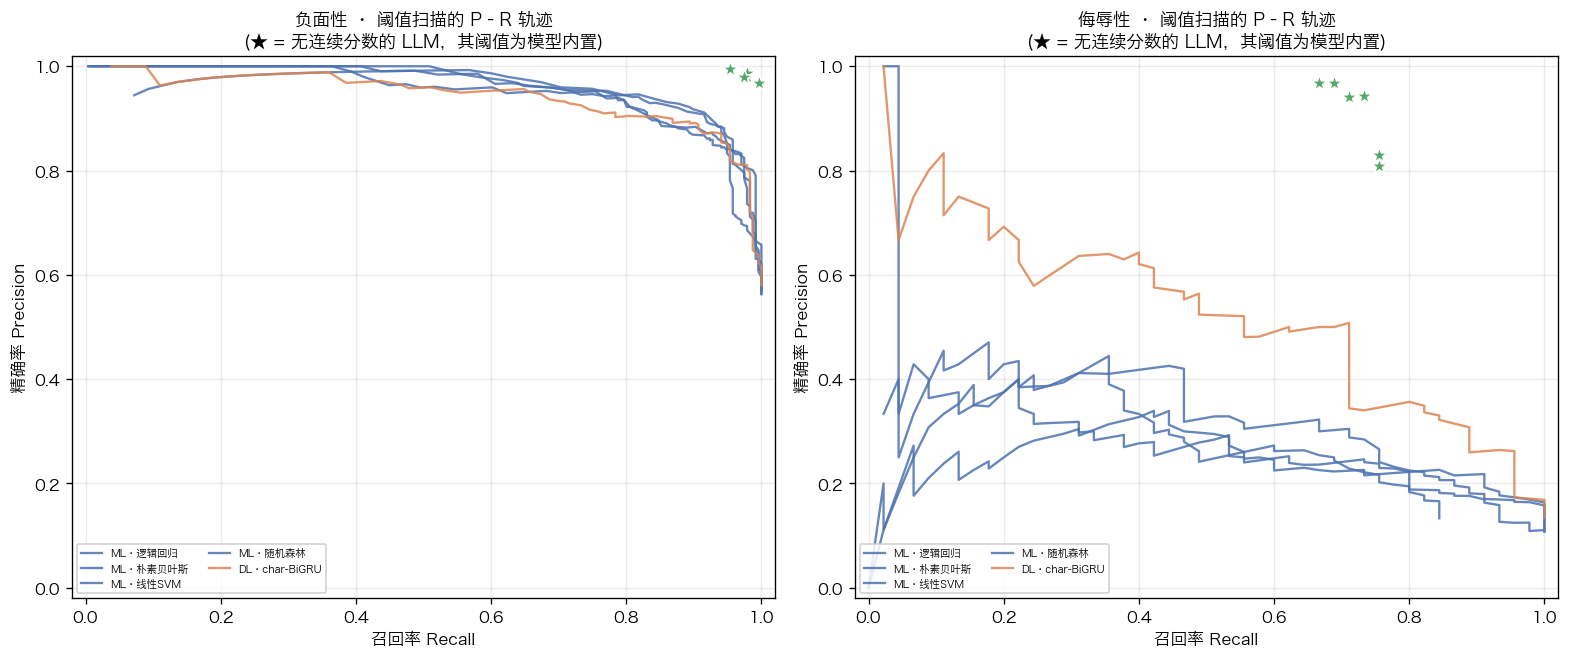

已保存 / saved: cmp_pr_curves.png

读图提示：
- 曲线越靠右上，方法在该任务上的可达性能上界越高。
- ML/DL 的曲线是"可调阈值能到达的所有 (R, P) 组合"；LLM 只有一个点，
  因为它只输出 0/1，其内置阈值不可调。
- 因此该图回答的是：**若给 ML/DL 自由选择阈值的权利，能否追平 LLM 的单点？**
  注意这是对 ML/DL 有利的比较（它们多了一个自由度），结论需按此方向解读。


In [27]:
# ===== 11.5 阈值敏感性：精确率–召回率轨迹 / threshold sensitivity =====
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.6))
for ax, dim in zip(axes, DIMS):
    k = DIMS.index(dim)
    for nm, v in METHODS.items():
        if v["score"] is None:
            continue
        s = v["score"][:, k]
        # 归一化到 [0,1] 便于跨算法比较（SVM 的 decision_function 尺度不同）
        s = (s - s.min()) / (s.max() - s.min() + 1e-12)
        ths = np.linspace(0.02, 0.98, 97)
        pts = []
        for t in ths:
            m = metrics_point(Y[:, k], (s >= t).astype(int))
            pts.append((m["Recall"], m["Precision"]))
        pts = np.array(pts)
        ax.plot(pts[:, 0], pts[:, 1], lw=1.4, alpha=0.85, label=nm,
                color=ROUTE_COLOR[v["route"]])
    # LLM 各配置只有单点
    for nm, v in METHODS.items():
        if v["score"] is not None:
            continue
        m = metrics_point(Y[:, k], v["pred"][:, k])
        ax.scatter(m["Recall"], m["Precision"], marker="*", s=110,
                   color=ROUTE_COLOR["LLM"], edgecolor="white", zorder=5)
    ax.set_xlabel("召回率 Recall"); ax.set_ylabel("精确率 Precision")
    ax.set_title(f"{dim} · 阈值扫描的 P–R 轨迹\n(★ = 无连续分数的 LLM，其阈值为模型内置)",
                 fontsize=10.5)
    ax.grid(alpha=0.25); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.legend(fontsize=6.2, loc="lower left", ncol=2, framealpha=0.85)

plt.tight_layout()
plt.savefig(OUT_DIR / "cmp_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close("all")
print("已保存 / saved: cmp_pr_curves.png")
print("""
读图提示：
- 曲线越靠右上，方法在该任务上的可达性能上界越高。
- ML/DL 的曲线是"可调阈值能到达的所有 (R, P) 组合"；LLM 只有一个点，
  因为它只输出 0/1，其内置阈值不可调。
- 因此该图回答的是：**若给 ML/DL 自由选择阈值的权利，能否追平 LLM 的单点？**
  注意这是对 ML/DL 有利的比较（它们多了一个自由度），结论需按此方向解读。""")


In [28]:
# ===== 11.6 提示模式的主效应 / effect of prompt engineering =====
PROMPT_ROWS = []
for mdl in LLM_MODELS:
    for k, dim in enumerate(DIMS):
        a = llm_pred[("零样本", mdl, dim)]
        b = llm_pred[("提示工程", mdl, dim)]
        b01, b10, or_, p = mcnemar_exact(Y[:, k], a, b)
        f1a = metrics_point(Y[:, k], a)["F1"]; f1b = metrics_point(Y[:, k], b)["F1"]
        PROMPT_ROWS.append({"模型": mdl, "维度": dim,
                            "F1_零样本": round(f1a, 4), "F1_提示工程": round(f1b, 4),
                            "ΔF1": round(f1b - f1a, 4),
                            "零样本错/工程对": b01, "零样本对/工程错": b10,
                            "OR": round(or_, 3) if np.isfinite(or_) else np.inf, "p_raw": p})
prompt_df = pd.DataFrame(PROMPT_ROWS)
# 在每个维度内部对 3 个模型做 Holm 校正
for dim in DIMS:
    msk = prompt_df["维度"] == dim
    prompt_df.loc[msk, "p_Holm"] = holm_bonferroni(prompt_df.loc[msk, "p_raw"].to_numpy())
prompt_df["显著"] = np.where(prompt_df["p_Holm"] < ALPHA, "是", "否")

print("【提示词工程是否带来增益（配对 McNemar，Holm 校正）】")
print(prompt_df.to_string(index=False))
n_sig = int((prompt_df["显著"] == "是").sum())
print(f"""
结论：{len(prompt_df)} 组配对比较中，Holm 校正后显著的有 {n_sig} 组。
{("→ 提示词工程未表现出可靠的增益。" if n_sig == 0 else "→ 部分模型/维度上提示词工程有显著增益，需逐条判断方向。")}""")


【提示词工程是否带来增益（配对 McNemar，Holm 校正）】
      模型  维度  F1_零样本  F1_提示工程     ΔF1  零样本错/工程对  零样本对/工程错    OR    p_raw   p_Holm 显著
    MiMo 负面性  0.9812   0.9812  0.0000         1         1 1.000 1.000000 1.000000  否
    MiMo 侮辱性  0.7816   0.8250  0.0434         7         2 3.500 0.179688 0.539062  否
Deepseek 负面性  0.9788   0.9766 -0.0022         3         4 0.750 1.000000 1.000000  否
Deepseek 侮辱性  0.8052   0.7895 -0.0157         3         4 0.750 1.000000 1.000000  否
    Qwen 负面性  0.9830   0.9740 -0.0090         2         6 0.333 0.289062 0.867188  否
    Qwen 侮辱性  0.7907   0.8101  0.0194         6         3 2.000 0.507812 1.000000  否

结论：6 组配对比较中，Holm 校正后显著的有 0 组。
→ 提示词工程未表现出可靠的增益。


In [29]:
# ===== 11.7 DL 与 LLM 的能力边界：AUPRC 对比（仅限有分数的方法） =====
rows = []
for nm, v in METHODS.items():
    if v["score"] is None:
        continue
    for k, dim in enumerate(DIMS):
        au, ap = auroc_auprc(Y[:, k], v["score"][:, k])
        rows.append({"方法": nm, "路线": v["route"], "维度": dim,
                     "AUROC": round(au, 4), "AUPRC": round(ap, 4)})
auc_df = pd.DataFrame(rows)
print("【AUROC / AUPRC（仅可输出连续分数的方法）】")
print(auc_df.to_string(index=False))
print(f"""
基准参考：侮辱性正类占比 {Y[:,1].mean():.3f}，因此随机分类器的 AUPRC ≈ {Y[:,1].mean():.3f}。
LLM 的该两项为 N/A —— 其输出是离散标签而非分数，无法计算排序类指标。
这构成一个**结构性不可比**：AUPRC 能刻画"整体排序质量"，
而 LLM 在这个维度上没有可观测的输出。结论中必须区分"LLM 未测"与"LLM 表现差"。""")


【AUROC / AUPRC（仅可输出连续分数的方法）】
           方法 路线  维度  AUROC  AUPRC
      ML·逻辑回归 ML 负面性 0.9552 0.9663
      ML·逻辑回归 ML 侮辱性 0.8250 0.3628
     ML·朴素贝叶斯 ML 负面性 0.9473 0.9595
     ML·朴素贝叶斯 ML 侮辱性 0.8022 0.2734
     ML·线性SVM ML 负面性 0.9604 0.9691
     ML·线性SVM ML 侮辱性 0.7733 0.2993
      ML·随机森林 ML 负面性 0.9330 0.9388
      ML·随机森林 ML 侮辱性 0.7367 0.2320
DL·char-BiGRU DL 负面性 0.9376 0.9436
DL·char-BiGRU DL 侮辱性 0.8954 0.5397

基准参考：侮辱性正类占比 0.107，因此随机分类器的 AUPRC ≈ 0.107。
LLM 的该两项为 N/A —— 其输出是离散标签而非分数，无法计算排序类指标。
这构成一个**结构性不可比**：AUPRC 能刻画"整体排序质量"，
而 LLM 在这个维度上没有可观测的输出。结论中必须区分"LLM 未测"与"LLM 表现差"。


---

## 12. 结论与局限

以下结论由上文代码**动态生成**，数字直接取自实际计算，
避免叙述与结果脱节。

In [30]:
# ===== 12. 结论（由数据驱动生成）/ data-driven conclusions =====
lines = []
for dim in DIMS:
    k = DIMS.index(dim)
    sub = main_df[main_df["维度"] == dim].sort_values("F1", ascending=False)
    top_all = sub.iloc[0]
    lines.append(f"\n【{dim}】")
    lines.append(f"  · F1 最高的配置：{top_all['方法']}（F1 = {top_all['F1']:.4f}，"
                 f"95% CI [{top_all['F1_lo']:.4f}, {top_all['F1_hi']:.4f}]）")

    # 各路线的最佳
    for route in ["ML", "DL", "LLM"]:
        rs = sub[sub["路线"] == route]
        if len(rs):
            b = rs.iloc[0]
            lines.append(f"  · {route} 最佳：{b['方法']}（F1 = {b['F1']:.4f}）")

    # 统计显著的对数
    nd = delta_df[delta_df["维度"] == dim]
    n_sig_pair = int((pair_df[(pair_df["维度"] == dim)]["显著"] == "是").sum())
    n_ci = int((nd["CI跨0"] == "否").sum())
    lines.append(f"  · 55 对比较中，McNemar+Holm 显著 {n_sig_pair} 对；"
                 f"ΔF1 的配对 CI 排除 0 的有 {n_ci} 对")

    # 对抗类型的共同盲区（直接从 type_df 取，避免依赖上游被覆盖的变量）
    if dim == "侮辱性":
        for t in ["声音型差评", "语气型差评", "视觉型差评"]:
            r = type_df[(type_df["维度"] == "侮辱性") & (type_df["类型"] == t)]
            lines.append(f"  · {t}（正类{int(r['正类数'].iloc[0])}）召回最高 "
                         f"{r['组内召回'].max():.3f}（{r.loc[r['组内召回'].idxmax(), '方法']}），"
                         f"最低 {r['组内召回'].min():.3f}")

concl = "\n".join(lines)
print(concl)

# ---- 自动化的关键判断 ----
print("\n" + "=" * 96)
print("【自动判定的关键结论】")
print("=" * 96)

# 1) 是否所有方法在侮辱性上都不显著
n_sig_ins = int((pair_df[(pair_df["维度"] == "侮辱性")]["显著"] == "是").sum())
print(f"1. 侮辱性维度：Holm 校正后显著的方法对 = {n_sig_ins} / 55")
print(f"   → {'差异主要表现为个别配对，整体同质性较强' if n_sig_ins < 10 else '方法间存在系统性差异'}")

# 2) 提示词工程
n_sig_prompt = int((prompt_df["显著"] == "是").sum())
print(f"\n2. 提示词工程：{len(prompt_df)} 组配对中显著 {n_sig_prompt} 组")
print(f"   → {'无可靠证据表明提示词工程带来增益' if n_sig_prompt == 0 else '存在部分显著增益'}")

# 3) DL 种子波动
dl_sd_ins = seed_df[seed_df["维度"] == "侮辱性"]["F1"].std(ddof=1)
gap_llm = (main_df[(main_df["维度"] == "侮辱性") & (main_df["路线"] == "LLM")]["F1"].max()
           - seed_df[seed_df["维度"] == "侮辱性"]["F1"].mean())
print(f"\n3. DL 在侮辱性上的种子标准差 = {dl_sd_ins:.4f}；"
      f"LLM 最佳与 DL 种子均值的差距 = {gap_llm:+.4f}")
print(f"   → 该差距{'**大于**' if abs(gap_llm) > 2*dl_sd_ins else '小于'} 2 倍种子标准差，"
      f"{'可视为超出随机波动' if abs(gap_llm) > 2*dl_sd_ins else '**不能**排除随机波动的影响'}")

# 4) 错误互补性
for dim in DIMS:
    kk = DIMS.index(dim)
    reps = {r: best_of(r, dim) for r in ["ML", "DL", "LLM"]}
    corr = {r: (METHODS[nm]["pred"][:, kk] == Y[:, kk]) for r, (nm, _) in reps.items()}
    uniq = int(sum(1 for i in range(N) if sum([corr["ML"][i], corr["DL"][i], corr["LLM"][i]]) == 1))
    allw = int(((~corr["ML"]) & (~corr["DL"]) & (~corr["LLM"])).sum())
    print(f"\n4.{DIMS.index(dim)+1} {dim}：仅一条路线判对 {uniq} 条（{uniq/N:.1%}），"
          f"三条全错 {allw} 条（{allw/N:.1%}）")



【负面性】
  · F1 最高的配置：LLM·Qwen·零样本（F1 = 0.9830，95% CI [0.9701, 0.9936]）
  · ML 最佳：ML·线性SVM（F1 = 0.9121）
  · DL 最佳：DL·char-BiGRU（F1 = 0.8798）
  · LLM 最佳：LLM·Qwen·零样本（F1 = 0.9830）
  · 55 对比较中，McNemar+Holm 显著 30 对；ΔF1 的配对 CI 排除 0 的有 32 对

【侮辱性】
  · F1 最高的配置：LLM·MiMo·提示工程（F1 = 0.8250，95% CI [0.7297, 0.9070]）
  · ML 最佳：ML·逻辑回归（F1 = 0.4242）
  · DL 最佳：DL·char-BiGRU（F1 = 0.4932）
  · LLM 最佳：LLM·MiMo·提示工程（F1 = 0.8250）
  · 55 对比较中，McNemar+Holm 显著 28 对；ΔF1 的配对 CI 排除 0 的有 36 对
  · 声音型差评（正类22）召回最高 0.818（LLM·MiMo·零样本），最低 0.000
  · 语气型差评（正类6）召回最高 0.667（ML·逻辑回归），最低 0.000
  · 视觉型差评（正类17）召回最高 0.882（LLM·Qwen·零样本），最低 0.000

【自动判定的关键结论】
1. 侮辱性维度：Holm 校正后显著的方法对 = 28 / 55
   → 方法间存在系统性差异

2. 提示词工程：6 组配对中显著 0 组
   → 无可靠证据表明提示词工程带来增益

3. DL 在侮辱性上的种子标准差 = 0.0763；LLM 最佳与 DL 种子均值的差距 = +0.4475
   → 该差距**大于** 2 倍种子标准差，可视为超出随机波动

4.1 负面性：仅一条路线判对 24 条（5.7%），三条全错 2 条（0.5%）

4.2 侮辱性：仅一条路线判对 18 条（4.3%），三条全错 7 条（1.7%）


### 局限（Limitations）

1. **样本规模与正类数量。** 侮辱性正类仅 45 条，其中语气型只有 6 条。
   所有涉及侮辱性的估计都带有很宽的置信区间；语气型上的任何差异**不具备**统计判别的能力，
   相关数字只能作为定性描述。所有结论都应理解为"在当前样本量下可获得的证据强度"。

2. **LLM 的不确定性未被量化。** ML 与 DL 都报告了随机性来源（折间、种子间），
   但 LLM 每个条件只调用一次，其采样方差未知。这是本对比中唯一的结构性不对称。
   缓解方式是降低对 LLM 之间细微差距的解释力度，只在差距明显超过其他方法的不确定性时才作判断。

3. **LLM 无法给出排序类指标。** AUROC / AUPRC 对 ML 与 DL 可算，对 LLM 为 N/A。
   这两组数字**不可直接比较**，"LLM 未测"不等于"LLM 表现差"。

4. **金标准本身带有噪声。** 见 §2.1 的信度指标。任何方法都无法超越标注一致性所设定的上限；
   若某方法的 F1 接近甚至超过标注者之间的复现水平，更合理的解释是它拟合了多数票而非真正"理解"了意图。

5. **提示词工程的实现只有一组。** 所谓"提示词工程"是一个宽泛空间，
   本 notebook 只检验了其中一种具体实现；结论不能推广为"提示工程整体无效"。

6. **类型标签是预设而非标注。** 分层分析中的「类型」来自数据集的预先分组，
   不是标注员判断的结果。它反映的是数据构造者的意图，不是受试者的自然类别。


---

## 13. 结果导出

所有表格与图形写入 `Data/Comparison/`。原始数据文件全程只读。

In [31]:
# ===== 13. 导出 / export all artifacts =====
EXPORT = {
    "cmp_main_metrics.csv": main_df,
    "cmp_pairwise_mcnemar.csv": pair_df,
    "cmp_cochran_q.csv": q_df,
    "cmp_delta_f1.csv": delta_df,
    "cmp_by_type.csv": type_df,
    "cmp_by_length.csv": len_df,
    "cmp_sensitivity.csv": sens_df,
    "cmp_dl_seeds.csv": seed_df,
    "cmp_hierarchy.csv": hier_df,
    "cmp_prompt_modes.csv": prompt_df,
    "cmp_ranking_metrics.csv": auc_df,
    "cmp_error_overlap.csv": overlap_df,
    "cmp_agreement.csv": agree_df,
}

# 预测矩阵（便于外部复现每个方法在每条样本上的预测）
pred_export = human[["类型", "评论"]].copy()
for nm, v in METHODS.items():
    for k, dim in enumerate(DIMS):
        pred_export[f"{nm}|{dim}"] = v["pred"][:, k]
pred_export.to_csv(OUT_DIR / "cmp_predictions_all.csv", index=False, encoding="utf-8-sig")
print(f"已保存 / saved: cmp_predictions_all.csv  ({pred_export.shape[0]}×{pred_export.shape[1]})")

for fn, dfv in EXPORT.items():
    dfv.to_csv(OUT_DIR / fn, index=False, encoding="utf-8-sig")
    print(f"已保存 / saved: {fn}  ({dfv.shape[0]}×{dfv.shape[1]})")

print("\n图形 / figures:")
for p in sorted(OUT_DIR.glob("cmp_*.png")):
    print(f"  {p.name:<34s} {p.stat().st_size/1024:>7.1f} KB")

print("\n源文件未被修改 / source files untouched:")
for name, h in FINGERPRINT.items():
    print(f"  {name:<28s} {h[:16]}…")


已保存 / saved: cmp_predictions_all.csv  (420×24)
已保存 / saved: cmp_main_metrics.csv  (22×29)
已保存 / saved: cmp_pairwise_mcnemar.csv  (110×10)
已保存 / saved: cmp_cochran_q.csv  (2×6)
已保存 / saved: cmp_delta_f1.csv  (110×9)
已保存 / saved: cmp_by_type.csv  (110×10)
已保存 / saved: cmp_by_length.csv  (66×8)
已保存 / saved: cmp_sensitivity.csv  (66×6)
已保存 / saved: cmp_dl_seeds.csv  (10×6)
已保存 / saved: cmp_hierarchy.csv  (10×8)
已保存 / saved: cmp_prompt_modes.csv  (6×11)
已保存 / saved: cmp_ranking_metrics.csv  (10×5)
已保存 / saved: cmp_error_overlap.csv  (2×7)
已保存 / saved: cmp_agreement.csv  (2×7)

图形 / figures:
  cmp_by_type.png                      162.5 KB
  cmp_delta_f1_matrix.png              211.2 KB
  cmp_forest_f1.png                    108.9 KB
  cmp_pr_curves.png                    132.9 KB

源文件未被修改 / source files untouched:
  Human_Result.csv             dbb563ba66a9de99…
  Human.csv                    74a7ac2cc678ef08…
  ML_predictions.csv           a276d2f9879a63a1…
  LLM_predictions.csv          cd